# 일본 RSV 유행의 지역별 관계와 4주 후 보고 수 예측: 분석 코드

최종보고서의 표와 그림, 본문에 나온 수치는 모두 이 노트북에서 나온다. `code/` 폴더의 스크립트 01~14를 보고서 순서대로 이어 붙인 것이라 내용은 스크립트와 같다(6.8절인 14가 부록 B인 13보다 앞에 온다).

위에서부터 순서대로 실행하면 된다. 자료는 `RSV_transmission_in_Japan/` 또는 `../일본 RSV/RSV_transmission_in_Japan/`에서 읽고, numpy, pandas, scikit-learn, scipy, matplotlib이 필요하다. 전체를 돌리는 데 15분쯤 걸린다. 대회 규정에 따라 외부 자료는 쓰지 않았다. 절 번호는 보고서의 장, 절 번호와 같게 맞췄다.

## 0. 준비

In [1]:
from pathlib import Path
from itertools import combinations
import os, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import font_manager as fm
import matplotlib.ticker as mticker
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

CANDIDATES = [Path('RSV_transmission_in_Japan'), Path('../일본 RSV/RSV_transmission_in_Japan'), Path('../RSV_transmission_in_Japan'), Path('.')]
DATA_DIR = next((p for p in CANDIDATES if (p / 'cases.csv').exists()), None)
assert DATA_DIR is not None, 'cases.csv 못 찾음'
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path('results'); OUT_DIR.mkdir(exist_ok=True)
print('DATA_DIR =', DATA_DIR)

B1, B2, B3 = '#2a78d6', '#eb6834', '#1baf7a'; INK = '#0b0b0b'; INK2 = '#52514e'; MUTED = '#898781'; GRID = '#e1e0d9'; BASE = '#c3c2b7'
SEQ = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']

# 한글 폰트
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # findfont 경고가 너무 많이 떠서
_avail = {f.name for f in fm.fontManager.ttflist}
KFONT = next((f for f in ['Malgun Gothic', 'AppleGothic', 'Noto Sans CJK KR', 'NanumGothic'] if f in _avail), 'DejaVu Sans')
print('그림 글꼴:', KFONT)
plt.rcParams.update({'font.family': KFONT,
                     'font.size': 8.3, 'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 9.2,
                     'axes.titleweight': 'normal', 'axes.titlelocation': 'left', 'axes.unicode_minus': False,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.facecolor': 'white', 'legend.frameon': False, 'legend.fontsize': 7.8})

def clean(ax, ygrid=True):
    for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
    ax.tick_params(length=0)
    if ygrid: ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

def dot(ax, x, y, col, **kw):
    ax.plot(x, y, color=col, linewidth=1.3, marker='o', markersize=4.6, markeredgecolor='white', markeredgewidth=1.0, **kw)

WD = 6.7  # inch

DATA_DIR = RSV_transmission_in_Japan
그림 글꼴: Noto Sans CJK KR


공통 함수는 한 셀에 모아 두었다. `code/rsv_core.py`와 같은 코드다. 자료 읽기, 인근 현 고르기, 예측용 표 만들기, 연도별 평가, 지표 계산, 현 단위 부트스트랩 순서다.

In [2]:
def save(df, name, index=False):
    df.to_csv(OUT_DIR / name, index=index, encoding='utf-8-sig')  # 엑셀에서 한글 안 깨지게

def facts(name, d):
    # 표로 만들기 애매한 낱개 숫자. 보고서 본문에 쓰는 값은 여기서 읽어 감
    save(pd.Series(d, name='value').rename_axis('key').reset_index(), f'facts_{name}.csv')

# 기상 파일 쪽 표기가 다름 (Naoasaki는 오타인 듯)
FIX = {'Hyōgo': 'Hyogo', 'Naoasaki': 'Nagasaki'}

def load(d):
    c = pd.read_csv(os.path.join(d, 'cases.csv'), index_col=0)
    pop = pd.read_csv(os.path.join(d, 'population.csv'), thousands=',')
    pop['prefecture'] = pop.prefecture.str.replace(r'-(ken|fu|to)$', '', regex=True)  # Aichi-ken -> Aichi
    W = c.pivot(index='time', columns='prefecture', values='cases').sort_index()
    yw = c.drop_duplicates('time').set_index('time')[['year', 'week']].sort_index()
    info = c.groupby('prefecture')[['lat', 'long']].first().join(pop.set_index('prefecture')[['pop', 'island']])
    info = info.loc[W.columns]
    return c, W, yw, info

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def distance_matrix(info):
    la, lo = info.lat.to_numpy(), info.long.to_numpy()
    return haversine(la[:, None], lo[:, None], la[None, :], lo[None, :])

def nearest_k(info, k=3):
    D = distance_matrix(info).copy(); np.fill_diagonal(D, np.inf)  # 자기 자신 제외
    idx = np.argsort(D, axis=1)[:, :k]
    names = info.index.to_numpy()
    return {names[i]: list(names[idx[i]]) for i in range(len(names))}

def nb_weights(info, k=3, kind='near', start=0, seed=None):
    # 행이 대상 현, 열이 평균에 들어가는 현. rank는 가까운 순으로 start번째부터 k곳 (먼 현 대조용)
    D = distance_matrix(info).copy(); np.fill_diagonal(D, np.inf)
    n = len(info); isl = info.island.to_numpy(); rng = np.random.default_rng(seed)
    Wt = np.zeros((n, n))
    for i in range(n):
        d = D[i].copy()
        if kind == 'island' and (isl == isl[i]).sum() > 1:  # 홋카이도, 오키나와는 같은 섬에 다른 현이 없어서 그대로 둠
            d[isl != isl[i]] = np.inf
        if kind == 'random':
            pick = rng.choice(np.delete(np.arange(n), i), size=k, replace=False)
        elif kind == 'pop':  # 거리와 상관없이 인구가 가장 비슷한 k곳
            gap = np.abs(np.log(info['pop'].to_numpy()) - np.log(info['pop'].to_numpy()[i])); gap[i] = np.inf
            pick = np.argsort(gap)[:k]
        else:
            pick = np.argsort(d)[start:start + k]
            pick = pick[np.isfinite(d[pick])]
        w = 1 / D[i, pick] if kind == 'invdist' else np.ones(len(pick))
        Wt[i, pick] = w / w.sum()
    return pd.DataFrame(Wt, index=info.index, columns=info.index)

def build_panel(W, yw, info, h=4, k=3, nb_lag=0, nb_w=None, nat_lag=0):
    # nb_lag=1이면 인근 값을 한 주 늦게 씀 (공개 지연 점검용). nat_lag는 전국 합계에 같은 처리
    # nb_w를 주면 가까운 k곳 평균 대신 그 가중치로 인근 평균을 만듦
    L = np.log1p(W)  # 0이 많아서 log1p
    NAT = np.log1p(W.sum(axis=1)).shift(nat_lag)
    nb = nearest_k(info, k)
    if nb_w is not None:
        NBM = pd.DataFrame(L.to_numpy() @ nb_w.loc[W.columns, W.columns].to_numpy().T, index=L.index, columns=L.columns)
    T = W.index.to_numpy()
    rows = []
    for p in W.columns:
        s = L[p]
        nbm = (L[nb[p]].mean(axis=1) if nb_w is None else NBM[p]).shift(nb_lag)
        df = pd.DataFrame({
            'time': T, 'pref': p, 'y_now': W[p].to_numpy(), 'y_tgt': W[p].shift(-h).to_numpy(),
            'l0': s, 'l1': s.shift(1), 'l2': s.shift(2), 'l3': s.shift(3), 'd4': s - s.shift(4),
            'nb0': nbm, 'nb_d4': nbm - nbm.shift(4), 'nb_gap': nbm - s,
            'nat0': NAT, 'nat_d4': NAT - NAT.shift(4),
            # 아래는 최종보고서 6.1절에서 시험한 입력. M0~M4에는 안 들어감
            'nb_d1': nbm - nbm.shift(1), 'nb_d2': nbm - nbm.shift(2), 'nat_d1': NAT - NAT.shift(1), 'nat_d2': NAT - NAT.shift(2),
            'pk': s - s.rolling(8, min_periods=1).max(), 'nb_pk': nbm - nbm.rolling(8, min_periods=1).max(),
            'cum': np.log1p(W[p].rolling(26, min_periods=1).mean()) - np.log1p(W[p].expanding().mean()), 'typ': s.expanding().mean(),
        }).reset_index(drop=True)  # 이거 없으면 아래 merge에서 time이 인덱스랑 겹쳐서 에러남
        rows.append(df)
    P = pd.concat(rows, ignore_index=True)
    P = P.merge(yw.rename(columns={'year': 'o_year', 'week': 'o_week'}), left_on='time', right_index=True)
    P['t_time'] = P.time + h
    P = P.merge(yw.rename(columns={'year': 't_year', 'week': 't_week'}), left_on='t_time', right_index=True, how='left')
    # 2015, 2020년은 53주라서 52 대신 365.25/7
    P['ws'] = np.sin(2 * np.pi * P.t_week / 52.18); P['wc'] = np.cos(2 * np.pi * P.t_week / 52.18)
    P['tgt_log'] = np.log1p(P.y_tgt)
    return P

OWN = ['l0', 'l1', 'l2', 'l3', 'd4', 'ws', 'wc']
NB = ['nb0', 'nb_d4', 'nb_gap']
NAT = ['nat0', 'nat_d4']
MODELS = {'M1 자기 현 이력': OWN, 'M2 인근 3현 추가': OWN + NB, 'M3 전국 추가': OWN + NAT, 'M4 인근과 전국 추가': OWN + NB + NAT}
M0, M1, M2, M3, M4 = ['M0 현재값 유지'] + list(MODELS)

def ridge(alpha=1.0):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

def train_rows(P, yw, Y, need=()):
    # 목표 시점 기준으로 자름. 예측 시점으로 자르면 작년 마지막 4주 행의 목표값이 올해 값이 됨
    y0 = yw.index[yw.year == Y].min()
    return P[(P.t_time < y0)].dropna(subset=OWN + NB + NAT + list(need) + ['tgt_log'])

def evaluate_years(P, W, yw, years=(2021, 2022, 2023), alpha=1.0, models=None, learner=None, keep=None):
    # models, learner, keep을 안 주면 중간보고서에서 고정한 설계 그대로
    # keep: 학습 행을 골라내는 함수 (특이 관측을 빼고 다시 학습할 때)
    models = MODELS if models is None else models
    learner = (lambda: ridge(alpha)) if learner is None else learner
    need = sorted({c for cols in models.values() for c in cols} - set(OWN + NB + NAT))
    out = []
    for Y in years:
        y0 = yw.index[yw.year == Y].min()
        te = P[(P.o_year == Y) & (P.t_year == Y)].copy()
        tr = train_rows(P, yw, Y, need)
        if keep is not None: tr = tr[keep(tr)]
        te = te.dropna(subset=OWN + NB + NAT + need + ['tgt_log'])
        scale = W.loc[W.index < y0].mean().clip(lower=1.0)  # 규모 보정 MAE 분모
        te['scale'] = te.pref.map(scale)
        te['pred_' + M0] = te.y_now
        for name, cols in models.items():
            m = learner().fit(tr[cols], tr.tgt_log)
            te['pred_' + name] = np.clip(np.expm1(m.predict(te[cols])), 0, None)
        te['eval_year'] = Y
        out.append(te)
    return pd.concat(out, ignore_index=True)

def metrics(df, pcol):
    e = df[pcol] - df.y_tgt
    return pd.Series({'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean()),
                      'logMAE': (np.log1p(df[pcol]) - np.log1p(df.y_tgt)).abs().mean(),
                      'scaledMAE': (e.abs() / df.scale).mean(), 'n': len(df)})

def log_mae(df, name):
    return (np.log1p(df['pred_' + name]) - np.log1p(df.y_tgt)).abs().mean()

def cluster_boot_diff(df, pa, pb, B=2000, seed=0):
    # 같은 현 행끼리는 독립이 아니라서 현 단위로 뽑음. 음수면 pa가 나음
    rng = np.random.default_rng(seed)
    ea = (np.log1p(df[pa]) - np.log1p(df.y_tgt)).abs(); eb = (np.log1p(df[pb]) - np.log1p(df.y_tgt)).abs()
    g = pd.DataFrame({'p': df.pref.to_numpy(), 'a': ea.to_numpy(), 'b': eb.to_numpy()}).groupby('p').agg(['sum', 'count'])
    sa, sb, n = g[('a', 'sum')].to_numpy(), g[('b', 'sum')].to_numpy(), g[('a', 'count')].to_numpy()
    k = len(sa); idx = rng.integers(0, k, size=(B, k))
    d = sa[idx].sum(1) / n[idx].sum(1) - sb[idx].sum(1) / n[idx].sum(1)
    point = sa.sum() / n.sum() - sb.sum() / n.sum()
    return point, np.quantile(d, 0.025), np.quantile(d, 0.975)

def effect_table(E, pairs, years=(2021, 2022, 2023)):
    rows = []
    for Y in list(years) + ['전체']:
        d = E if Y == '전체' else E[E.eval_year == Y]
        for a, b in pairs:
            pt, lo, hi = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
            rows.append({'연도': Y, '비교': f'{a} - {b}', '차이': pt, '하한': lo, '상한': hi})
    return pd.DataFrame(rows)

def block_boot_diff(df, pa, pb, block=8, B=2000, seed=0):
    # 현 단위 부트스트랩은 같은 주에 여러 현이 함께 틀리는 것을 못 잡음. 예측 시점을 8주씩 묶어서 묶음 단위로도 뽑아 봄
    rng = np.random.default_rng(seed)
    ea = (np.log1p(df[pa]) - np.log1p(df.y_tgt)).abs(); eb = (np.log1p(df[pb]) - np.log1p(df.y_tgt)).abs()
    key = df.eval_year.astype(int) * 100 + (df.o_week.astype(int) - 1) // block
    g = pd.DataFrame({'k': key.to_numpy(), 'd': (ea - eb).to_numpy()}).groupby('k').d.agg(['sum', 'count'])
    s_, n_ = g['sum'].to_numpy(), g['count'].to_numpy()
    idx = rng.integers(0, len(g), size=(B, len(g)))
    d = s_[idx].sum(1) / n_[idx].sum(1)
    return s_.sum() / n_.sum(), np.quantile(d, 0.025), np.quantile(d, 0.975)

def peak_lead(E, W, yw, info, a=M2, b=M1):
    # 현과 연도마다 정점 1주 전~2주 후에 낸 예측(목표는 정점 3~6주 뒤)의 로그 편향과, 인근 3현 정점이 자기 현보다 얼마나 늦은지
    nb = nearest_k(info)
    ea = np.log1p(E['pred_' + a]) - E.tgt_log; eb = np.log1p(E['pred_' + b]) - E.tgt_log
    rows = []
    for Y in sorted(E.eval_year.unique()):
        t = yw.index[yw.year == Y]; wk = yw.loc[t, 'week'].to_numpy()
        pk = {p: int(yw.loc[W.loc[t, p].idxmax(), 'week']) for p in W.columns}
        com = {p: (W.loc[t, p].to_numpy() * wk).sum() / W.loc[t, p].sum() for p in W.columns}
        for p in W.columns:
            m = ((E.eval_year == Y) & (E.pref == p) & E.o_week.between(pk[p] - 1, pk[p] + 2)).to_numpy()
            if m.sum() < 3: continue  # 정점이 연말이면 목표 주가 다음 해로 넘어가서 행이 없음
            rows.append({'연도': Y, 'pref': p, '정점 주': pk[p], '인근 정점 − 자기 정점': np.mean([pk[q] for q in nb[p]]) - pk[p],
                         '인근 무게중심 − 자기 무게중심': np.mean([com[q] for q in nb[p]]) - com[p],
                         'M1 편향': eb[m].mean(), 'M2 편향': ea[m].mean(), '절대 오차 차이': (ea[m].abs() - eb[m].abs()).mean()})
    LD = pd.DataFrame(rows); LD['편향 차이'] = LD['M2 편향'] - LD['M1 편향']
    x = LD['인근 정점 − 자기 정점']
    LD['구분'] = np.where(x < -1, '인근이 1주 넘게 먼저', np.where(x > 1, '자기 현이 1주 넘게 먼저', '차이 1주 이내'))
    return LD

def boot_mean(v, g, B=2000, seed=0):
    # 값 v의 평균을 묶음 g(현) 단위로 다시 뽑아 95% 구간을 구함
    t = pd.DataFrame({'g': np.asarray(g), 'v': np.asarray(v)}).groupby('g').v.agg(['sum', 'count'])
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(t), size=(B, len(t)))
    d = t['sum'].to_numpy()[idx].sum(1) / t['count'].to_numpy()[idx].sum(1)
    return t['sum'].sum() / t['count'].sum(), np.quantile(d, 0.025), np.quantile(d, 0.975)

## 2. 자료 (보고서 2장)

제공 자료만 쓴다. 0인 주의 비율, 현 사이 규모 차이, 기상 자료가 끝나는 주, 인근 현까지의 거리를 확인한다. 본문에 쓰는 낱개 숫자는 `results/facts_*.csv`로 따로 남긴다.

In [3]:
c, W, yw, info = load(DATA_DIR)
print('보고 수:', W.shape, '| 기간:', tuple(yw.iloc[0]), '~', tuple(yw.iloc[-1]))

hum = pd.read_csv(DATA_DIR / 'humidity.csv', index_col=0)
bad = sorted(set(hum.key) - set(W.columns))
print('현 이름 불일치:', bad, '수정 후:', [FIX[k] for k in bad])
print('기상 자료 마지막 주:', hum.groupby('year').week.max().to_dict())  # 2020년 9주까지라 예측엔 못 씀

z = c.assign(period=np.select([c.year <= 2019, (c.year == 2020) | ((c.year == 2021) & (c.week <= 26))], ['2013~2019', '2020~2021년 26주'], '2021년 27주 이후'))
zero = z.groupby('period').cases.apply(lambda s: (s == 0).mean())
print('보고 수 0인 주의 비율:', zero.round(3).to_dict())

mu = W.loc[yw.index[yw.year <= 2019]].mean().sort_values()
print('2013~2019 주평균 보고 수: 가장 적은 현 %s %.1f건, 가장 많은 현 %s %.1f건' % (mu.index[0], mu.iloc[0], mu.index[-1], mu.iloc[-1]))

D = distance_matrix(info); Dn = D.copy(); np.fill_diagonal(Dn, np.inf)
s3 = np.sort(Dn, axis=1)[:, :3]
nb3 = nearest_k(info)
oki = list(info.index).index('Okinawa')
print('인근 3현까지 거리 중앙값 %.0f km, 최대 %.0f km' % (np.median(s3), s3.max()))
print('오키나와의 인근 3현:', nb3['Okinawa'], '| 가장 가까운 현까지 %.0f km' % Dn[oki].min())
cross = sum(info.island[p] != info.island[q] for p, v in nb3.items() for q in v)
print('다른 섬을 잇는 인근 연결:', cross, '/', 47 * 3)
vals = {'zero_pre': zero['2013~2019'], 'zero_covid': zero['2020~2021년 26주'], 'zero_post': zero['2021년 27주 이후'], 'mean_min': mu.iloc[0], 'mean_max': mu.iloc[-1],
         'nb_dist_median': np.median(s3), 'nb_dist_max': s3.max(), 'okinawa_nearest': Dn[oki].min(), 'cross_island': cross,
         'n_week': len(W), 'cases_max': int(W.to_numpy().max())}
facts('data', vals)

보고 수: (574, 47) | 기간: (2013, 1) ~ (2023, 52)
현 이름 불일치: ['Hyōgo', 'Naoasaki'] 수정 후: ['Hyogo', 'Nagasaki']
기상 자료 마지막 주: {2013: 52, 2014: 52, 2015: 52, 2016: 52, 2017: 52, 2018: 52, 2019: 52, 2020: 9}
보고 수 0인 주의 비율: {'2013~2019': 0.049, '2020~2021년 26주': 0.39, '2021년 27주 이후': 0.092}
2013~2019 주평균 보고 수: 가장 적은 현 Yamanashi 9.8건, 가장 많은 현 Osaka 190.1건
인근 3현까지 거리 중앙값 81 km, 최대 757 km
오키나와의 인근 3현: ['Kagoshima', 'Miyazaki', 'Nagasaki'] | 가장 가까운 현까지 657 km
다른 섬을 잇는 인근 연결: 19 / 141


## 3. 현 사이의 동조성 (보고서 3장, 3.1절)

그림 1은 47개 현의 전체 흐름이고, 그림 2는 거리 구간과 같은 섬 여부에 따른 현 쌍 상관이다. 2016년(전환기)과 2020년(공백)은 기간에서 뺐다. 오키나와가 든 쌍을 뺀 평균과 한 해씩 따로 계산한 평균 상관도 함께 구한다.

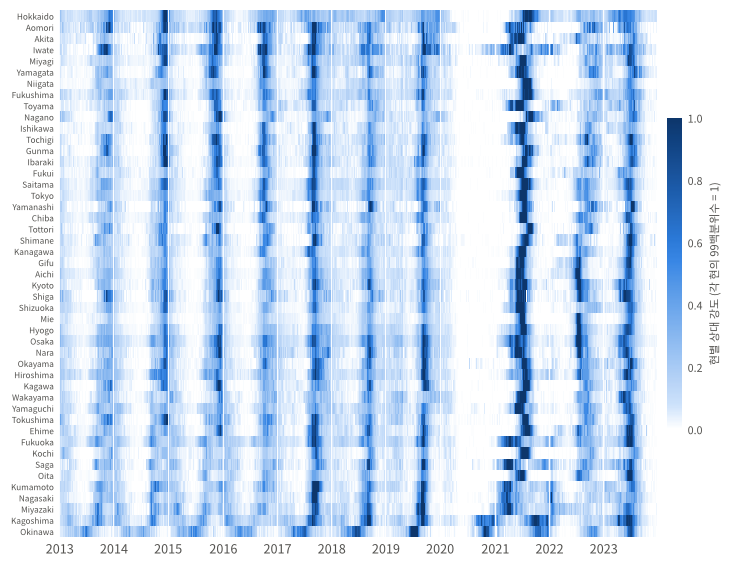

dbin                      <150  150–300  300–500  500–800  >800
period             same                                        
2013–2015 (겨울 유행기) False  0.83     0.80     0.69     0.63  0.30
                   True   0.83     0.81     0.81     0.78  0.73
2017–2019 (가을 유행기) False  0.78     0.76     0.69     0.63  0.38
                   True   0.79     0.73     0.71     0.68  0.67
2021–2023 (코로나 이후) False  0.73     0.57     0.46     0.52  0.37
                   True   0.74     0.63     0.65     0.62  0.58

,period,oki,mean,size
0,2013–2015 (겨울 유행기),False,0.59,155
1,2013–2015 (겨울 유행기),True,-0.78,42
2,2017–2019 (가을 유행기),False,0.56,155
3,2017–2019 (가을 유행기),True,-0.26,42
4,2021–2023 (코로나 이후),False,0.37,155
5,2021–2023 (코로나 이후),True,0.36,42


기간별 전체 평균 상관: {'2013–2015 (겨울 유행기)': 0.682, '2017–2019 (가을 유행기)': 0.648, '2021–2023 (코로나 이후)': 0.566}


,period,same,r
0,2013–2015 (겨울 유행기),True,0.805
1,2013–2015 (겨울 유행기),False,0.667
2,2017–2019 (가을 유행기),True,0.720
3,2017–2019 (가을 유행기),False,0.644
4,2021–2023 (코로나 이후),True,0.652
5,2021–2023 (코로나 이후),False,0.474


연도별 평균 상관: {2013: 0.68, 2014: 0.73, 2015: 0.67, 2016: 0.7, 2017: 0.7, 2018: 0.62, 2019: 0.64, 2020: 0.62, 2021: 0.47, 2022: 0.47, 2023: 0.79}


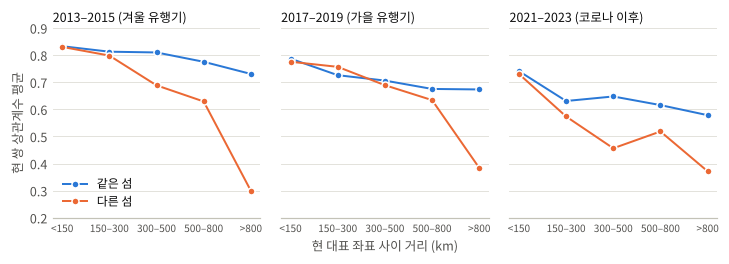

In [4]:
D = distance_matrix(info)

order = info.lat.sort_values(ascending=False).index
M = W[order].T
R = M.div(M.quantile(0.99, axis=1).replace(0, 1), axis=0).clip(upper=1.0)
yr0 = yw.reset_index().groupby('year').time.min()

fig, ax = plt.subplots(figsize=(WD, 5.2))
im = ax.imshow(R.to_numpy(), aspect='auto', cmap=LinearSegmentedColormap.from_list('seq', ['#ffffff'] + SEQ), vmin=0, vmax=1,
               interpolation='nearest', extent=[0.5, M.shape[1] + 0.5, len(order) - 0.5, -0.5])
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=5.4)
ax.set_xticks(yr0.values); ax.set_xticklabels(yr0.index.astype(str))
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0)
for t in yr0.values: ax.axvline(t - 0.5, color='white', linewidth=0.6)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.015); cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=7)
cb.set_label('현별 상대 강도 (각 현의 99백분위수 = 1)', color=INK2, fontsize=7.3)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig1_heatmap.png'); plt.show()

L = np.log1p(W); P = list(W.columns); idx = {p: i for i, p in enumerate(P)}; isl = info.island.to_dict()
# 2016(전환기), 2020(공백)은 뺌
periods = {'2013–2015 (겨울 유행기)': (2013, 2015), '2017–2019 (가을 유행기)': (2017, 2019), '2021–2023 (코로나 이후)': (2021, 2023)}
rows = []
for nm, (a, b) in periods.items():
    t = yw.index[(yw.year >= a) & (yw.year <= b)]
    Cm = np.corrcoef(L.loc[t].to_numpy().T)
    for p, q in combinations(P, 2):
        rows.append({'period': nm, 'r': Cm[idx[p], idx[q]], 'dist': D[idx[p], idx[q]], 'same': isl[p] == isl[q], 'oki': 'Okinawa' in (p, q)})
S = pd.DataFrame(rows)
bins = ['<150', '150–300', '300–500', '500–800', '>800']
S['dbin'] = pd.cut(S.dist, [0, 150, 300, 500, 800, 3000], labels=bins)
SC = S.groupby(['period', 'same', 'dbin'], observed=True).r.mean().unstack('dbin')  # same=True: 같은 섬
display(SC.round(2)); save(SC.reset_index(), 'sync_corr.csv')
save(S.groupby('period', sort=False).r.mean().rename('r').reset_index(), 'sync_mean.csv')
save(S.groupby(['period', 'same'], sort=False).r.mean().rename('r').reset_index(), 'sync_island.csv')
# 800 km 넘는 다른 섬 쌍은 여름에 유행하는 오키나와가 낀 쌍이 평균을 끌어내림
far = S[(S.dist > 800) & ~S.same].groupby(['period', 'oki'], sort=False).r.agg(['mean', 'size']).reset_index(); display(far.round(2)); save(far, 'sync_far.csv')
print('기간별 전체 평균 상관:', S.groupby('period', sort=False).r.mean().round(3).to_dict())
# 다른 섬 쌍의 평균은 오키나와가 낀 쌍에 크게 좌우됨. 오키나와를 뺀 평균도 따로 저장
SN = S[~S.oki].groupby(['period', 'same'], sort=False).r.mean().rename('r').reset_index(); save(SN, 'sync_island_nooki.csv'); display(SN.round(3))
# 세 해를 묶은 상관은 해마다 유행 시기가 달랐던 것까지 반영함. 한 해씩 따로 계산한 평균 상관
iu = np.triu_indices(len(P), 1)
SY = pd.DataFrame([{'year': Y, 'r': np.nanmean(np.corrcoef(L.loc[yw.index[yw.year == Y]].to_numpy().T)[iu])} for Y in sorted(yw.year.unique())])
save(SY, 'sync_year.csv'); print('연도별 평균 상관:', SY.set_index('year').r.round(2).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(WD, 2.45), sharey=True)
for ax, (per, g) in zip(axes, S.groupby('period', sort=False)):
    tb = g.groupby(['same', 'dbin'], observed=True).r.mean().unstack('dbin')[bins]
    x = np.arange(len(bins))
    dot(ax, x, tb.loc[True].values, B1, label='같은 섬'); dot(ax, x, tb.loc[False].values, B2, label='다른 섬')
    clean(ax); ax.set_xticks(x); ax.set_xticklabels(bins, fontsize=6.6); ax.set_title(per, fontsize=8.2, pad=4); ax.set_ylim(0.2, 0.9)
axes[0].set_ylabel('현 쌍 상관계수 평균'); axes[1].set_xlabel('현 대표 좌표 사이 거리 (km)'); axes[0].legend(loc='lower left')
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig2_sync.png'); plt.show()

### 3.2 유행 시기를 비교하는 지표 (그림 3)

52주 창의 시작 주를 바꿔 가며 최고 주와 무게중심이 얼마나 흔들리는지 본다. 6.5절에서 무게중심을 기본 지표로 쓰는 근거다.

,start,n_peak_last_week,Honshu_peak,Honshu_com,Kyushu_peak,Kyushu_com,Shikoku_peak,Shikoku_com
0,1,0,8.0,5.12,27.0,6.93,5.5,4.06
1,14,1,7.0,5.58,24.0,7.87,5.5,2.85
2,27,13,29.0,3.91,1.0,4.23,38.0,2.52
3,40,0,4.0,2.86,3.0,2.19,2.5,2.22


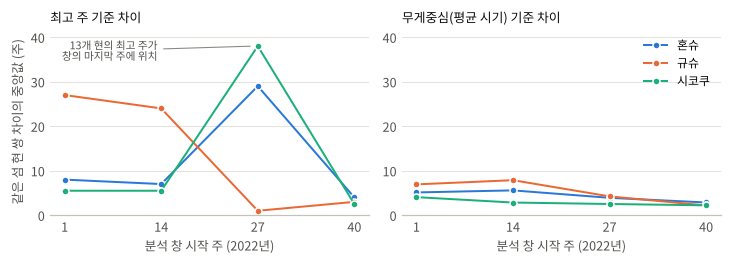

In [5]:
P = list(W.columns); idx = {p: i for i, p in enumerate(P)}; isl = info.island.to_dict()

res = []
for s in (1, 14, 27, 40):
    t0 = yw.index[(yw.year == 2022) & (yw.week == s)][0]
    arr = W.loc[t0:t0 + 51].to_numpy()
    pk = arr.argmax(0)
    com = (arr * np.arange(52)[:, None]).sum(0) / arr.sum(0)
    out = {'start': s, 'n_peak_last_week': int((pk == 51).sum())}
    for I in ('Honshu', 'Kyushu', 'Shikoku'):  # 홋카이도, 오키나와는 현이 하나뿐
        ps = [p for p in P if isl[p] == I]
        out[f'{I}_peak'] = np.median([abs(pk[idx[x]] - pk[idx[y]]) for x, y in combinations(ps, 2)])
        out[f'{I}_com'] = round(float(np.median([abs(com[idx[x]] - com[idx[y]]) for x, y in combinations(ps, 2)])), 2)
    res.append(out)
SB = pd.DataFrame(res); display(SB); save(SB, 'season_boundary.csv')

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.45))
for ax, key, ttl in [(axes[0], 'peak', '최고 주 기준 차이'), (axes[1], 'com', '무게중심(평균 시기) 기준 차이')]:
    for I, col, lab in [('Honshu', B1, '혼슈'), ('Kyushu', B2, '규슈'), ('Shikoku', B3, '시코쿠')]:
        dot(ax, SB.start, SB[f'{I}_{key}'], col, label=lab)
    clean(ax); ax.set_xticks(SB.start); ax.set_xlabel('분석 창 시작 주 (2022년)'); ax.set_title(ttl, fontsize=8.4, pad=4); ax.set_ylim(0, 42)
axes[0].set_ylabel('같은 섬 현 쌍 차이의 중앙값 (주)'); axes[1].legend(loc='upper right')
# 글자 위치는 눈으로 맞춤
axes[0].annotate('13개 현의 최고 주가\n창의 마지막 주에 위치', (26.4, 38), xytext=(13.5, 37), fontsize=7, color=INK2, ha='right', va='center',
                 arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=0.7))
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig3_boundary.png'); plt.show()

## 4~5. 예측 방법과 결과 (보고서 4장, 5.1~5.2절)

중간보고서에서 고정한 설계 그대로다. 4주 앞 예측, 2021~2023년을 한 해씩 평가, 릿지(α = 1), 모델 M0~M4. 표 2, 표 3, 그림 4와 차이의 신뢰구간이 여기서 나온다.

In [6]:
Pn = build_panel(W, yw, info, h=4, k=3)
E = evaluate_years(Pn, W, yw)
print('연도별 평가 행 수:', E.groupby('eval_year').size().to_dict())

names = ['M0 현재값 유지'] + list(MODELS)
rows = []
for Y in (2021, 2022, 2023):
    d = E[E.eval_year == Y]
    rows += [{'연도': str(Y), '모델': nm, **metrics(d, 'pred_' + nm).to_dict()} for nm in names]
rows += [{'연도': '전체', '모델': nm, **metrics(E, 'pred_' + nm).to_dict()} for nm in names]
T1 = pd.DataFrame(rows); T1.to_csv(OUT_DIR / 'metrics_by_year.csv', index=False, encoding='utf-8-sig')
display(T1.round({'MAE': 2, 'RMSE': 2, 'logMAE': 3, 'scaledMAE': 3}))

YRS = ['2021', '2022', '2023', '전체']
T2 = T1.pivot(index='모델', columns='연도', values='logMAE').loc[names, YRS].round(3)
display(T2)
T3 = T1.pivot(index='모델', columns='연도', values=['MAE', 'RMSE']).swaplevel(axis=1)
T3 = T3[[(y, k) for y in YRS for k in ('MAE', 'RMSE')]].loc[names].round(1)
display(T3)
print('2022년 규모 보정 MAE: M1 %.3f, M2 %.3f' % tuple(T1[(T1['연도'] == '2022') & T1['모델'].isin(['M1 자기 현 이력', 'M2 인근 3현 추가'])].scaledMAE))

연도별 평가 행 수: {2021: 2256, 2022: 2256, 2023: 2256}


,연도,모델,MAE,RMSE,logMAE,scaledMAE,n
0,2021,M0 현재값 유지,72.26,162.57,0.917,1.766,2256.0
1,2021,M1 자기 현 이력,71.77,155.71,0.961,1.762,2256.0
2,2021,M2 인근 3현 추가,65.08,145.83,0.865,1.606,2256.0
3,2021,M3 전국 추가,71.35,156.37,0.911,1.788,2256.0
4,2021,M4 인근과 전국 추가,66.84,145.96,0.861,1.688,2256.0
5,2022,M0 현재값 유지,34.35,89.41,0.771,0.706,2256.0
6,2022,M1 자기 현 이력,29.35,81.01,0.686,0.631,2256.0
7,2022,M2 인근 3현 추가,31.31,93.62,0.668,0.672,2256.0
8,2022,M3 전국 추가,32.11,91.36,0.673,0.677,2256.0
9,2022,M4 인근과 전국 추가,32.39,94.63,0.670,0.699,2256.0


연도,2021,2022,2023,전체
모델,,,,
M0 현재값 유지,0.917,0.771,0.805,0.831
M1 자기 현 이력,0.961,0.686,0.808,0.818
M2 인근 3현 추가,0.865,0.668,0.685,0.739
M3 전국 추가,0.911,0.673,0.683,0.756
M4 인근과 전국 추가,0.861,0.670,0.662,0.731


연도            2021         2022        2023          전체       
               MAE   RMSE   MAE  RMSE   MAE  RMSE   MAE   RMSE
모델                                                            
M0 현재값 유지     72.3  162.6  34.3  89.4  40.8  77.4  49.1  116.1
M1 자기 현 이력    71.8  155.7  29.3  81.0  38.0  73.5  46.4  109.9
M2 인근 3현 추가   65.1  145.8  31.3  93.6  33.1  66.4  43.2  107.1
M3 전국 추가      71.3  156.4  32.1  91.4  34.4  68.4  45.9  111.8
M4 인근과 전국 추가  66.8  146.0  32.4  94.6  33.1  66.3  44.1  107.5

2022년 규모 보정 MAE: M1 0.631, M2 0.672


,연도,비교,차이,하한,상한
0,2021,M2 인근 3현 추가 - M1 자기 현 이력,-0.096,-0.119,-0.071
6,2022,M2 인근 3현 추가 - M1 자기 현 이력,-0.019,-0.032,-0.006
12,2023,M2 인근 3현 추가 - M1 자기 현 이력,-0.123,-0.137,-0.109
18,전체,M2 인근 3현 추가 - M1 자기 현 이력,-0.079,-0.092,-0.066


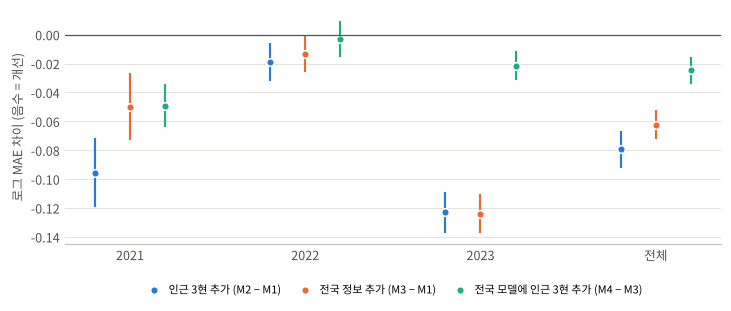

,연도,비교,차이,하한,상한
5,2021,M1 자기 현 이력 - M0 현재값 유지,0.043,0.019,0.068
11,2022,M1 자기 현 이력 - M0 현재값 유지,-0.085,-0.107,-0.063
17,2023,M1 자기 현 이력 - M0 현재값 유지,0.003,-0.016,0.023
23,전체,M1 자기 현 이력 - M0 현재값 유지,-0.013,-0.027,0.001
4,2021,M2 인근 3현 추가 - M0 현재값 유지,-0.053,-0.086,-0.022
10,2022,M2 인근 3현 추가 - M0 현재값 유지,-0.104,-0.131,-0.076
16,2023,M2 인근 3현 추가 - M0 현재값 유지,-0.120,-0.146,-0.092
22,전체,M2 인근 3현 추가 - M0 현재값 유지,-0.092,-0.113,-0.071
3,2021,M2 인근 3현 추가 - M3 전국 추가,-0.046,-0.067,-0.024
9,2022,M2 인근 3현 추가 - M3 전국 추가,-0.005,-0.023,0.012


In [7]:
# 앞의 셋이 그림 4
pairs = [('M2 인근 3현 추가', 'M1 자기 현 이력'), ('M3 전국 추가', 'M1 자기 현 이력'), ('M4 인근과 전국 추가', 'M3 전국 추가'),
         ('M2 인근 3현 추가', 'M3 전국 추가'), ('M2 인근 3현 추가', 'M0 현재값 유지'), ('M1 자기 현 이력', 'M0 현재값 유지')]
cis = []
for Y in (2021, 2022, 2023, '전체'):
    d = E if Y == '전체' else E[E.eval_year == Y]
    for a, b in pairs:
        pt, lo, hi = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
        cis.append({'연도': Y, '비교': f'{a} - {b}', '차이': pt, '하한': lo, '상한': hi})
CI = pd.DataFrame(cis)
display(CI[CI['비교'] == 'M2 인근 3현 추가 - M1 자기 현 이력'].round(3))

fig, ax = plt.subplots(figsize=(WD, 2.95))
cats = [2021, 2022, 2023, '전체']
labels = ['인근 3현 추가 (M2 − M1)', '전국 정보 추가 (M3 − M1)', '전국 모델에 인근 3현 추가 (M4 − M3)']
for j, ((a, b), lab, col) in enumerate(zip(pairs[:3], labels, [B1, B2, B3])):
    sub = CI[CI['비교'] == f'{a} - {b}']
    xs = np.arange(len(cats)) + (j - 1) * 0.2  # 겹치지 않게
    ax.vlines(xs, sub['하한'], sub['상한'], color=col, linewidth=1.4)
    ax.plot(xs, sub['차이'], 'o', color=col, markersize=5, markeredgecolor='white', markeredgewidth=1.0, label=lab, linestyle='none')
ax.axhline(0, color=INK2, linewidth=0.8); clean(ax); ax.set_xticks(range(len(cats))); ax.set_xticklabels([str(x) for x in cats])
ax.set_ylabel('로그 MAE 차이 (음수 = 개선)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=7.2, handletextpad=0.3, columnspacing=1.2)
fig.tight_layout(); fig.subplots_adjust(bottom=0.24); fig.savefig(FIG_DIR / 'fig4_effects.png'); plt.show()
CI.to_csv(OUT_DIR / 'effects_ci.csv', index=False, encoding='utf-8-sig')

show = ['M4 인근과 전국 추가 - M3 전국 추가', 'M3 전국 추가 - M1 자기 현 이력', 'M2 인근 3현 추가 - M3 전국 추가',
        'M1 자기 현 이력 - M0 현재값 유지', 'M2 인근 3현 추가 - M0 현재값 유지']
display(CI[CI['비교'].isin(show)].sort_values(['비교', '연도'], key=lambda s: s.astype(str)).round(3))

### 5.3 2022년에는 원래 단위의 오차가 오히려 커졌다 (그림 5)

2022년에 늘어난 제곱 오차가 어느 현, 어느 주에서 나왔는지 본다.

제곱 오차 증가분 중 상위 3개 현의 비중: 0.82 {'Osaka': 2610664.0, 'Aichi': 1004666.0, 'Hyogo': 474152.0}


,pref,o_week,t_week,y_now,y_tgt,pred_M1 자기 현 이력,pred_M2 인근 3현 추가
3820,Osaka,29,33.0,1428,526.0,1225.6,1861.9
3819,Osaka,28,32.0,1280,688.0,1134.1,1820.5
3821,Osaka,30,34.0,1253,454.0,942.1,1369.7
2283,Aichi,28,32.0,1097,307.0,857.8,1203.1
2284,Aichi,29,33.0,916,162.0,744.6,997.7
2859,Hyogo,28,32.0,675,439.0,708.1,1063.8
2285,Aichi,30,34.0,769,84.0,533.8,773.1
2860,Hyogo,29,33.0,694,344.0,866.0,1064.1


2022년 정점 주: {'Aichi': 28, 'Osaka': 29, 'Hyogo': 30}


,o_week,t_week,y_now,y_tgt,pred_M1 자기 현 이력,pred_M2 인근 3현 추가
3820,29,33.0,1428,526.0,1226.0,1862.0


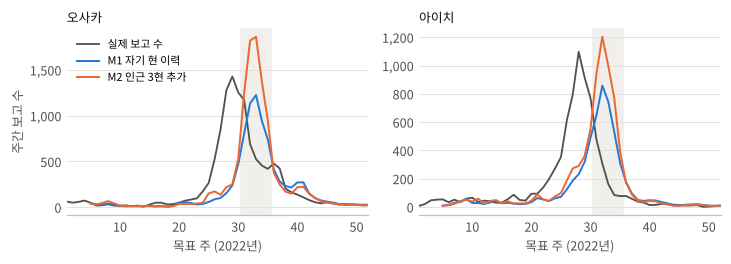

In [8]:
E = evaluate_years(build_panel(W, yw, info, h=4, k=3), W, yw)

d = E[E.eval_year == 2022].copy()
a, b = 'pred_M2 인근 3현 추가', 'pred_M1 자기 현 이력'
d['dSE'] = (d[a] - d.y_tgt)**2 - (d[b] - d.y_tgt)**2  # +면 M2가 더 틀림
bp = d.groupby('pref').dSE.sum().sort_values(ascending=False)
print('제곱 오차 증가분 중 상위 3개 현의 비중: %.2f' % (bp.head(3).sum() / d.dSE.sum()), bp.head(3).round(0).to_dict())
save(pd.DataFrame({'pref': bp.index, 'dSE': bp.values, 'share': bp.values / d.dSE.sum()}), 'error2022_by_pref.csv')
display(d.sort_values('dSE', ascending=False).head(8)[['pref', 'o_week', 't_week', 'y_now', 'y_tgt', b, a]].round(1))

peak = {p: int(yw.loc[W[p].loc[yw.index[yw.year == 2022]].idxmax(), 'week']) for p in ['Aichi', 'Osaka', 'Hyogo']}
print('2022년 정점 주:', peak)
# 본문 오사카 예시 (29주에 33주 예측)
display(d[(d.pref == 'Osaka') & (d.o_week == 29)][['o_week', 't_week', 'y_now', 'y_tgt', b, a]].round(0))
save(d[d.pref.isin(['Aichi', 'Osaka', 'Hyogo']) & d.o_week.between(27, 31)][['pref', 'o_week', 't_week', 'y_now', 'y_tgt', b, a]].assign(peak=lambda x: x.pref.map(peak)), 'error2022_rows.csv')

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.45))
for ax, p, nm in [(axes[0], 'Osaka', '오사카'), (axes[1], 'Aichi', '아이치')]:
    g = d[d.pref == p].sort_values('t_week'); obs = W[p].loc[yw.index[yw.year == 2022]]
    ax.plot(np.arange(1, len(obs) + 1), obs.values, color=INK2, linewidth=1.2, label='실제 보고 수')
    ax.plot(g.t_week, g[b], color=B1, linewidth=1.3, label='M1 자기 현 이력'); ax.plot(g.t_week, g[a], color=B2, linewidth=1.3, label='M2 인근 3현 추가')
    ax.axvspan(30.5, 35.5, color='#f0efec', zorder=0)  # 31~35주
    clean(ax); ax.set_xlim(1, 52); ax.set_xlabel('목표 주 (2022년)'); ax.set_title(nm, fontsize=8.4, pad=4)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, q: f'{int(v):,}'))
axes[0].set_ylabel('주간 보고 수'); axes[0].legend(loc='upper left', fontsize=7.2)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig5_2022_examples.png'); plt.show()

### 5.4 유행 단계별 오차 (표 4)

목표 시점 보고 수가 예측 시점의 1.2배보다 많으면 상승, 예측 시점 보고 수가 목표 시점의 1.2배보다 많으면 하강으로 나눴다. 끝의 1주 지연 확인은 중간보고서 5.5절에 있던 것이고, 최종보고서에서는 6.3절로 옮겼다.

In [9]:
E = evaluate_years(build_panel(W, yw, info, h=4, k=3), W, yw)

a, b = 'pred_M2 인근 3현 추가', 'pred_M1 자기 현 이력'
# 20%는 그냥 정한 기준. 15%, 25%로 바꾼 결과는 12_sensitivity.py
E['phase'] = np.where(E.y_tgt > E.y_now * 1.2, '상승', np.where(E.y_tgt < E.y_now / 1.2, '하강', '정체'))
lm = lambda x, col: (np.log1p(x[col]) - np.log1p(x.y_tgt)).abs().mean()
rows4 = []
for ph in ['상승', '하강', '정체']:
    for Y in (2021, 2022, 2023):
        x = E[(E.phase == ph) & (E.eval_year == Y)]
        rows4.append({'단계': ph, '연도': Y, '행 수': len(x), 'M1': lm(x, b), 'M2': lm(x, a)})
T4 = pd.DataFrame(rows4).round(3).set_index(['단계', '연도']).unstack('연도').swaplevel(axis=1)
T4 = T4[[(Y, k) for Y in (2021, 2022, 2023) for k in ('행 수', 'M1', 'M2')]].loc[['상승', '하강', '정체']]
display(T4); save(pd.DataFrame(rows4), 'phase_by_year.csv')

E1 = evaluate_years(build_panel(W, yw, info, h=4, k=3, nb_lag=1), W, yw)  # 중간보고서 5.5절. 2주 지연과 전국 합계 지연은 09_delay.py
own = metrics(E, 'pred_M1 자기 현 이력').logMAE
same = metrics(E, 'pred_M2 인근 3현 추가').logMAE
lag1 = metrics(E1, 'pred_M2 인근 3현 추가').logMAE
print(f'세 해 전체 로그 MAE: M1 {own:.3f} | M2 같은 주 {same:.3f} | M2 1주 지연 {lag1:.3f} | 개선분 유지율 {(own - lag1) / (own - same):.0%}')

연도 2021               2022                2023              
    행 수     M1     M2  행 수     M1     M2   행 수     M1     M2
단계                                                          
상승  954  1.203  1.065  893  0.855  0.787   862  0.962  0.837
하강  855  1.075  0.930  944  0.688  0.677  1077  0.843  0.683
정체  447  0.225  0.313  419  0.324  0.393   317  0.268  0.277

세 해 전체 로그 MAE: M1 0.818 | M2 같은 주 0.739 | M2 1주 지연 0.748 | 개선분 유지율 88%


## 6. 추가 분석 (보고서 6장)

여기부터는 중간보고서 뒤에 더한 분석이다. 위의 설계에서 한 가지씩만 바꿔서 다시 계산한다. 관측을 빼거나 예측 기간을 바꾸는 분석은 평가 행이 달라져서 행 수를 함께 적었다.

### 6.1 2022년 정점 직후 과대 예측 (표 5, 6, 7, 그림 6, 7)

세 현의 예측을 입력 묶음별로 나누고, 감소 전환을 잡는 입력을 시험하고, 인근 현과 자기 현의 정점 순서에 따라 M2와 M1의 오차가 어떻게 갈리는지 본다. 정점 순서는 지나고 나서야 알 수 있어서 사후 진단이다. 입력 E, F와 마지막 인구 확인은 부록 A에 적은 것이다.

In [10]:
P = build_panel(W, yw, info)
E = evaluate_years(P, W, yw)
BIG3 = ['Osaka', 'Aichi', 'Hyogo']
KOR = {'Osaka': '오사카', 'Aichi': '아이치', 'Hyogo': '효고'}

자기 현 수준  자기 현 4주 변화     계절  인근 수준  인근 4주 변화  전국 수준  \
pref  모델                                                                 
Osaka M1 자기 현 이력      3.434       0.384  0.259    NaN       NaN    NaN   
      M2 인근 3현 추가     3.408       0.126  0.179 -0.019     0.772    NaN   
      M4 인근과 전국 추가    3.323       0.104  0.184 -0.263     0.687  0.278   
Aichi M1 자기 현 이력      3.142       0.191  0.259    NaN       NaN    NaN   
      M2 인근 3현 추가     3.135       0.062  0.179 -0.017     0.553    NaN   
      M4 인근과 전국 추가    3.060       0.052  0.184 -0.232     0.492  0.278   
Hyogo M1 자기 현 이력      2.862       0.515  0.259    NaN       NaN    NaN   
      M2 인근 3현 추가     2.820       0.168  0.179 -0.018     0.786    NaN   
      M4 인근과 전국 추가    2.744       0.139  0.184 -0.244     0.700  0.278   

                    전국 4주 변화        예측  y_tgt  예측/실제  
pref  모델                                              
Osaka M1 자기 현 이력         NaN   969.580  651.6  1.574  
      M2 인근 3현 추가        NaN  1449.003  651.6  2.323  
      M4 인근과 전국 추가     0.108  1388.820  651.6  2.222  
Aichi M1 자기 현 이력         NaN   618.885  221.2  3.380  
      M2 인근 3현 추가        NaN   861.555  221.2  4.660  
      M4 인근과 전국 추가     0.108   888.677  221.2  4.799  
Hyogo M1 자기 현 이력         NaN   639.345  403.4  1.613  
      M2 인근 3현 추가        NaN   849.003  403.4  2.177  
      M4 인근과 전국 추가     0.108   827.457  403.4  2.121

오사카 29주: M1 1226건, M2 1862건 | M2의 인근 4주 변화 항 0.862 (2.37배), M1과 M2의 자기 현 변화 항 0.459, 0.150
2022년 정점 주와 인근 3현의 정점 주: {'Osaka': (29, {'Nara': 31, 'Hyogo': 30, 'Kyoto': 31}), 'Aichi': (28, {'Gifu': 30, 'Mie': 28, 'Shiga': 31}), 'Hyogo': (30, {'Osaka': 29, 'Wakayama': 38, 'Nara': 31})}


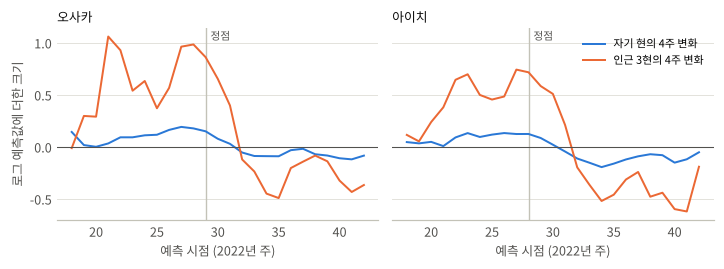

In [11]:
# 1) 입력 묶음이 예측값(로그)에 더한 크기. 기준은 학습 자료의 평균
def contrib(Y, cols, rows):
    tr = train_rows(P, yw, Y)
    m = ridge().fit(tr[cols], tr.tgt_log)
    sc, rg = m.named_steps['standardscaler'], m.named_steps['ridge']
    b = pd.Series(rg.coef_ / sc.scale_, index=cols); mu = pd.Series(sc.mean_, index=cols)
    con = (rows[cols] - mu) * b
    # nb_gap = nb0 - l0 이라 그대로 두면 자기 현 수준이 인근 쪽으로 섞여 들어감. 수준 항으로 다시 나눔
    bg = b.get('nb_gap', 0.0)
    g = pd.DataFrame({'자기 현 수준': con[['l0', 'l1', 'l2', 'l3']].sum(axis=1) - bg * (rows.l0 - mu.l0),
                      '자기 현 4주 변화': con.d4, '계절': con[['ws', 'wc']].sum(axis=1)})
    if 'nb0' in cols:
        g['인근 수준'] = con.nb0 + bg * (rows.nb0 - mu.nb0); g['인근 4주 변화'] = con.nb_d4
    if 'nat0' in cols:
        g['전국 수준'] = con.nat0; g['전국 4주 변화'] = con.nat_d4
    g['절편'] = rg.intercept_
    assert np.allclose(g.sum(axis=1), m.predict(rows[cols]))
    return g

sel = P[(P.o_year == 2022) & P.pref.isin(BIG3) & P.o_week.between(27, 31)]
parts = []
for nm in (M1, M2, M4):
    g = contrib(2022, MODELS[nm], sel)
    g.insert(0, '모델', nm); g.insert(1, 'pref', sel.pref); g.insert(2, 'o_week', sel.o_week)
    g['y_now'] = sel.y_now; g['y_tgt'] = sel.y_tgt; g['예측'] = np.expm1(g.drop(columns=['모델', 'pref', 'o_week', 'y_now', 'y_tgt']).sum(axis=1))
    parts.append(g)
DC = pd.concat(parts, ignore_index=True); save(DC, 'peak2022_decomp.csv')
gcols = ['자기 현 수준', '자기 현 4주 변화', '계절', '인근 수준', '인근 4주 변화', '전국 수준', '전국 4주 변화']
T5 = DC.groupby(['pref', '모델'])[gcols + ['예측', 'y_tgt']].mean().loc[BIG3]
T5['예측/실제'] = DC.assign(r=np.log1p(DC['예측']) - np.log1p(DC.y_tgt)).groupby(['pref', '모델']).r.mean().apply(np.exp)
display(T5.round(3)); save(T5.reset_index(), 'peak2022_decomp_mean.csv')
o = DC[(DC.pref == 'Osaka') & (DC.o_week == 29)].set_index('모델')
print('오사카 29주: M1 %.0f건, M2 %.0f건 | M2의 인근 4주 변화 항 %.3f (%.2f배), M1과 M2의 자기 현 변화 항 %.3f, %.3f' % (
    o.loc[M1, '예측'], o.loc[M2, '예측'], o.loc[M2, '인근 4주 변화'], np.exp(o.loc[M2, '인근 4주 변화']), o.loc[M1, '자기 현 4주 변화'], o.loc[M2, '자기 현 4주 변화']))
nb3 = nearest_k(info)
t22 = yw.index[yw.year == 2022]
pk22 = {p: int(yw.loc[W.loc[t22, p].idxmax(), 'week']) for p in W.columns}
print('2022년 정점 주와 인근 3현의 정점 주:', {p: (pk22[p], {q: pk22[q] for q in nb3[p]}) for p in BIG3})
save(pd.DataFrame([{'pref': p, '정점 주': pk22[p], **{f'인근{i + 1}': q for i, q in enumerate(nb3[p])}, **{f'인근{i + 1} 정점 주': pk22[q] for i, q in enumerate(nb3[p])}} for p in BIG3]), 'peak2022_weeks.csv')

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.5), sharey=True)
for ax, p in zip(axes, ['Osaka', 'Aichi']):
    r = P[(P.o_year == 2022) & (P.pref == p) & P.o_week.between(18, 42)]
    g = contrib(2022, MODELS[M2], r)
    ax.axvline(pk22[p], color=BASE, linewidth=0.9)
    ax.plot(r.o_week, g['자기 현 4주 변화'], color=B1, linewidth=1.3, label='자기 현의 4주 변화')
    ax.plot(r.o_week, g['인근 4주 변화'], color=B2, linewidth=1.3, label='인근 3현의 4주 변화')
    ax.axhline(0, color=INK2, linewidth=0.7); clean(ax); ax.set_xlabel('예측 시점 (2022년 주)'); ax.set_title(KOR[p], fontsize=8.4, pad=4)
    ax.text(pk22[p] + 0.4, 1.12, '정점', fontsize=7, color=INK2, va='top')
axes[0].set_ylabel('로그 예측값에 더한 크기'); axes[1].legend(loc='upper right', fontsize=7.2)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig6_decomp.png'); plt.show()

In [12]:
# 2) 감소 전환을 잡으려고 넣어 본 입력. 2022년 오차를 보고 고른 것들이라 2021, 2023년 결과를 같이 봄
P['nb_d4_dn'] = P.nb_d4 * (P.pk < 0)  # 자기 현이 최근 8주 최고치에서 내려온 뒤에는 인근 변화의 계수를 따로 둠
lp = np.log(info['pop']); relpop = pd.Series({p: lp[p] - np.mean([lp[q] for q in nb3[p]]) for p in W.columns})
P['nb_d4_pop'] = P.nb_d4 * P.pref.map(relpop)  # 인근보다 인구가 많은 현은 인근 변화를 덜 따르게
SETS = {'기본(M1~M4)': ([], [], []),
        'A 최근 1~2주 변화': ([], ['nb_d1', 'nb_d2'], ['nat_d1', 'nat_d2']),
        'B 최근 8주 최고치 대비 수준': (['pk'], ['nb_pk'], []),
        'C 최근 26주 평균(장기 평균 대비)': (['cum'], [], []),
        'D 자기 현 하락 뒤의 인근 변화': (['pk'], ['nb_d4_dn'], []),
        'E 현의 평소 수준': (['typ'], [], []),  # E, F는 부록 A에만 적음
        'F 인근 대비 인구와 인근 변화의 곱': ([], ['nb_d4_pop'], [])}
ratio = lambda d, m: float(np.exp((np.log1p(d['pred_' + m]) - np.log1p(d.y_tgt)).mean()))
rows = []; EC = None
for nm, (own, nbx, natx) in SETS.items():
    mods = {M1: OWN + own, M2: OWN + own + NB + nbx, M3: OWN + own + NAT + natx, M4: OWN + own + NB + nbx + NAT + natx}
    Ei = evaluate_years(P, W, yw, models=mods)
    if nm.startswith('C'): EC = Ei
    b3 = Ei[(Ei.eval_year == 2022) & Ei.pref.isin(BIG3) & Ei.o_week.between(27, 31)]; d22 = Ei[Ei.eval_year == 2022]
    ef = effect_table(Ei, [(M2, M1), (M4, M3)]); ef = ef[ef['연도'] == '전체'].set_index('비교')
    r = {'입력': nm}
    for m in (M1, M2, M3, M4): r['logMAE ' + m[:2]] = log_mae(Ei, m)
    for m in (M1, M2): r['2022 RMSE ' + m[:2]] = np.sqrt(((d22['pred_' + m] - d22.y_tgt)**2).mean())
    for m in (M1, M2): r['세 현 예측/실제 ' + m[:2]] = ratio(b3, m)
    for k, a in (('M2-M1', f'{M2} - {M1}'), ('M4-M3', f'{M4} - {M3}')):
        r[k] = ef.loc[a, '차이']; r[k + ' 하한'] = ef.loc[a, '하한']; r[k + ' 상한'] = ef.loc[a, '상한']
    rows.append(r)
T6 = pd.DataFrame(rows); save(T6, 'peak2022_inputs.csv'); display(T6.round(3))
display(effect_table(EC, [(M2, M1), (M4, M3)]).round(3))  # C를 넣은 모델끼리의 연도별 차이

,입력,logMAE M1,logMAE M2,logMAE M3,logMAE M4,2022 RMSE M1,2022 RMSE M2,세 현 예측/실제 M1,세 현 예측/실제 M2,M2-M1,M2-M1 하한,M2-M1 상한,M4-M3,M4-M3 하한,M4-M3 상한
0,기본(M1~M4),0.818,0.739,0.756,0.731,81.006,93.621,2.047,2.867,-0.079,-0.092,-0.066,-0.025,-0.034,-0.016
1,A 최근 1~2주 변화,0.818,0.739,0.753,0.729,81.006,93.246,2.047,2.828,-0.079,-0.093,-0.066,-0.024,-0.034,-0.015
2,B 최근 8주 최고치 대비 수준,0.815,0.733,0.756,0.727,80.377,90.621,1.975,2.759,-0.082,-0.095,-0.069,-0.029,-0.039,-0.019
3,C 최근 26주 평균(장기 평균 대비),0.764,0.704,0.717,0.701,78.918,91.871,2.236,2.919,-0.059,-0.071,-0.048,-0.016,-0.025,-0.008
4,D 자기 현 하락 뒤의 인근 변화,0.815,0.739,0.756,0.731,80.377,94.799,1.975,2.912,-0.076,-0.089,-0.063,-0.025,-0.034,-0.016
5,E 현의 평소 수준,0.810,0.727,0.749,0.723,80.212,95.901,2.148,2.997,-0.083,-0.097,-0.068,-0.025,-0.035,-0.016
6,F 인근 대비 인구와 인근 변화의 곱,0.818,0.739,0.756,0.731,81.006,89.036,2.047,2.574,-0.080,-0.093,-0.067,-0.025,-0.034,-0.016


,연도,비교,차이,하한,상한
0,2021,M2 인근 3현 추가 - M1 자기 현 이력,-0.073,-0.095,-0.050
1,2021,M4 인근과 전국 추가 - M3 전국 추가,-0.034,-0.047,-0.020
2,2022,M2 인근 3현 추가 - M1 자기 현 이력,-0.013,-0.026,-0.002
3,2022,M4 인근과 전국 추가 - M3 전국 추가,0.003,-0.007,0.014
4,2023,M2 인근 3현 추가 - M1 자기 현 이력,-0.091,-0.105,-0.078
5,2023,M4 인근과 전국 추가 - M3 전국 추가,-0.018,-0.028,-0.009
6,전체,M2 인근 3현 추가 - M1 자기 현 이력,-0.059,-0.071,-0.048
7,전체,M4 인근과 전국 추가 - M3 전국 추가,-0.016,-0.025,-0.008


현×연도 139개 | 정점 순서와 절대 오차 차이의 순위 상관: {'2021': 0.69, '2022': 0.42, '2023': 0.61, '전체': 0.55} | 전체 95% 구간 [0.38, 0.68]
정점 순서와 편향 차이의 순위 상관 0.71 | 무게중심 차이로 바꿨을 때 절대 오차 차이와의 순위 상관 0.48


,구분,현×연도,M1 편향,M2 편향,절대 오차 차이,하한,상한
0,인근이 1주 넘게 먼저,57,0.700,0.506,-0.135,-0.180,-0.092
1,차이 1주 이내,35,0.724,0.726,-0.005,-0.034,0.028
2,자기 현이 1주 넘게 먼저,47,0.341,0.518,0.118,0.070,0.163


차이 13주 이내 128개만: {'인근이 1주 넘게 먼저': -0.147, '자기 현이 1주 넘게 먼저': 0.123, '차이 1주 이내': -0.005} | 순위 상관 0.59


n                d              
연도             2021 2022 2023   2021   2022   2023
구분                                                
인근이 1주 넘게 먼저     21   19   17 -0.171 -0.063 -0.171
자기 현이 1주 넘게 먼저   14   18   15  0.149  0.146  0.056
차이 1주 이내         12    8   15  0.043 -0.016 -0.037

세 현(2022): [{'pref': 'Aichi', '정점 주': 28, '인근 정점 − 자기 정점': 1.67, 'M1 편향': 1.17, 'M2 편향': 1.52, '절대 오차 차이': 0.34}, {'pref': 'Hyogo', '정점 주': 30, '인근 정점 − 자기 정점': 2.67, 'M1 편향': 0.66, 'M2 편향': 0.74, '절대 오차 차이': 0.09}, {'pref': 'Osaka', '정점 주': 29, '인근 정점 − 자기 정점': 1.67, 'M1 편향': 0.66, 'M2 편향': 1.04, '절대 오차 차이': 0.38}]


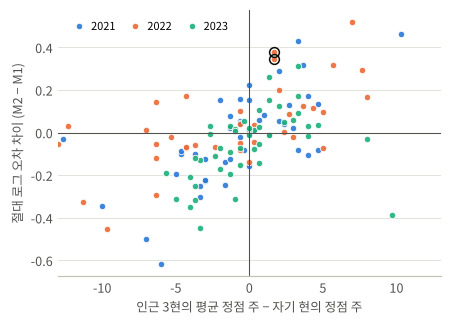

In [13]:
# 3) 인근보다 먼저 정점에 이른 현에서 인근 정보가 해가 되는가 (사후 진단. 정점은 지나고 나서야 알 수 있음)
LD = peak_lead(E, W, yw, info); save(LD, 'peak_lead.csv')
x, y = '인근 정점 − 자기 정점', '절대 오차 차이'
rho = {str(Y): spearmanr(d[x], d[y])[0] for Y, d in LD.groupby('연도')}; rho['전체'] = spearmanr(LD[x], LD[y])[0]
rng = np.random.default_rng(0); prefs = LD.pref.unique(); bs = []
for _ in range(2000):  # 한 현이 세 해에 걸쳐 나오니까 현 단위로 뽑음
    s = pd.concat([LD[LD.pref == q] for q in rng.choice(prefs, len(prefs))])
    bs.append(spearmanr(s[x], s[y])[0])
print('현×연도 %d개 | 정점 순서와 절대 오차 차이의 순위 상관: %s | 전체 95%% 구간 [%.2f, %.2f]' % (len(LD), {k: round(float(v), 2) for k, v in rho.items()}, *np.quantile(bs, [0.025, 0.975])))
# 편향 차이는 M2 예측과 M1 예측의 로그 차이라서 실제값이 안 들어감. 모델이 어떻게 움직이는지 보는 용도
rho_bias = spearmanr(LD[x], LD['편향 차이'])[0]
rho_com = spearmanr(LD['인근 무게중심 − 자기 무게중심'], LD[y])[0]  # 최고 주는 잡음이 커서 무게중심으로도 확인
print('정점 순서와 편향 차이의 순위 상관 %.2f | 무게중심 차이로 바꿨을 때 절대 오차 차이와의 순위 상관 %.2f' % (rho_bias, rho_com))
rows = []
for k in ('인근이 1주 넘게 먼저', '차이 1주 이내', '자기 현이 1주 넘게 먼저'):
    d = LD[LD['구분'] == k]; pt, lo, hi = boot_mean(d[y], d.pref)
    rows.append({'구분': k, '현×연도': len(d), 'M1 편향': d['M1 편향'].mean(), 'M2 편향': d['M2 편향'].mean(), y: pt, '하한': lo, '상한': hi})
T7 = pd.DataFrame(rows); display(T7.round(3)); save(T7, 'peak_lead_groups.csv')
# 최고 주가 연초나 연말에 잡혀 차이가 13주를 넘는 조합(그림 7에서 잘라낸 것)을 빼도 같은지
trim = LD[LD[x].abs() <= 13]; tg = trim.groupby('구분')[y].mean()
print('차이 13주 이내 %d개만: %s | 순위 상관 %.2f' % (len(trim), tg.round(3).to_dict(), spearmanr(trim[x], trim[y])[0]))
facts('lead', {'n': len(LD), **{'rho_' + k: v for k, v in rho.items()}, 'rho_lo': np.quantile(bs, 0.025), 'rho_hi': np.quantile(bs, 0.975), 'rho_bias': rho_bias, 'rho_com': rho_com,
               'clip': int((LD[x].abs() > 13).sum()), 'trim_nb': tg['인근이 1주 넘게 먼저'], 'trim_same': tg['차이 1주 이내'], 'trim_own': tg['자기 현이 1주 넘게 먼저'],
               'trim_rho': spearmanr(trim[x], trim[y])[0]})
display(LD.groupby(['연도', '구분']).agg(n=('pref', 'size'), d=(y, 'mean')).round(3).unstack('연도'))
print('세 현(2022):', LD[(LD['연도'] == 2022) & LD.pref.isin(BIG3)][['pref', '정점 주', x, 'M1 편향', 'M2 편향', y]].round(2).to_dict('records'))

fig, ax = plt.subplots(figsize=(WD * 0.62, 3.0))
for Y, col in ((2021, B1), (2022, B2), (2023, B3)):
    d = LD[LD['연도'] == Y]
    ax.plot(d[x], d[y], 'o', color=col, markersize=4.2, markeredgecolor='white', markeredgewidth=0.6, alpha=0.9, label=str(Y), linestyle='none')
b = LD[(LD['연도'] == 2022) & LD.pref.isin(['Osaka', 'Aichi'])]  # 글자를 붙이면 다른 점과 겹쳐서 테두리로만 표시
ax.plot(b[x], b[y], 'o', markersize=6.4, markerfacecolor='none', markeredgecolor=INK, markeredgewidth=1.0, linestyle='none')
ax.axhline(0, color=INK2, linewidth=0.7); ax.axvline(0, color=INK2, linewidth=0.7); clean(ax)
ax.set_xlim(-13, 13)  # 최고 주가 연초나 연말에 잡힌 현은 차이가 수십 주로 나와서 그림에서는 잘라냄
ax.set_xlabel('인근 3현의 평균 정점 주 − 자기 현의 정점 주'); ax.set_ylabel('절대 로그 오차 차이 (M2 − M1)'); ax.legend(loc='upper left', fontsize=7.2, ncol=3, columnspacing=0.8, handletextpad=0.1)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig7_lead.png'); plt.show()

In [14]:
# 인구가 많은 현이 인근보다 먼저 정점에 이르는지 (부록 A). 그렇다면 인구로 앞서는 현을 미리 가려낼 수 있음
for Y, d in LD.groupby('연도'):
    print(Y, '인근 대비 인구와 (인근 정점 − 자기 정점)의 순위 상관: %.2f (p = %.2f)' % spearmanr(d.pref.map(relpop), d[x]))
save(pd.DataFrame([{'연도': Y, 'rho': spearmanr(d.pref.map(relpop), d[x])[0], 'p': spearmanr(d.pref.map(relpop), d[x])[1]} for Y, d in LD.groupby('연도')]), 'peak_lead_pop.csv')

2021 인근 대비 인구와 (인근 정점 − 자기 정점)의 순위 상관: -0.13 (p = 0.38)
2022 인근 대비 인구와 (인근 정점 − 자기 정점)의 순위 상관: 0.06 (p = 0.72)
2023 인근 대비 인구와 (인근 정점 − 자기 정점)의 순위 상관: 0.20 (p = 0.18)


### 6.2 인근 현 정의 바꾸기 (표 8, 그림 8)

현의 수, 같은 섬, 거리 가중을 바꿔 보고, 섬별 효과를 나눈다. 뒤쪽은 대조 실험이다. 가까운 3현 대신 거리 순으로 더 먼 3현, 인구가 비슷한 3현, 무작위 3현을 넣었을 때 이득이 남는지 본다. 거리 순위마다 주 묶음으로 다시 뽑은 구간도 구한다. 무작위 200번 때문에 1분쯤 걸린다.

In [15]:
PAIRS = [(M2, M1), (M4, M3)]

def run(nb_w=None, k=3):
    return evaluate_years(build_panel(W, yw, info, k=k, nb_w=nb_w), W, yw)

def summary(E, label):
    ef = effect_table(E, PAIRS)
    r = {'인근 정의': label, 'M2': log_mae(E, M2), 'M4': log_mae(E, M4)}
    for a, b in PAIRS:
        x = ef[ef['비교'] == f'{a} - {b}'].set_index('연도')
        for Y in (2021, 2022, 2023, '전체'):
            r[f'{a[:2]}-{b[:2]} {Y}'] = x.loc[Y, '차이']
        r[f'{a[:2]}-{b[:2]} 하한'] = x.loc['전체', '하한']; r[f'{a[:2]}-{b[:2]} 상한'] = x.loc['전체', '상한']
    return r

In [16]:
# 1) 현의 수, 같은 섬, 거리 가중
D = distance_matrix(info); Dn = D.copy(); np.fill_diagonal(Dn, np.inf)
defs = [(f'가까운 {k}현' + (' (기본)' if k == 3 else ''), dict(k=k)) for k in range(1, 6)]
defs += [('같은 섬 안에서 가까운 3현', dict(nb_w=nb_weights(info, 3, 'island'))),
         ('가까운 3현, 거리 역수 가중', dict(nb_w=nb_weights(info, 3, 'invdist'))),
         ('가까운 5현, 거리 역수 가중', dict(nb_w=nb_weights(info, 5, 'invdist')))]
E3 = run()
T8 = pd.DataFrame([summary(run(**kw), nm) for nm, kw in defs]); save(T8, 'neighbor_defs.csv'); display(T8.round(3))
wi = nb_weights(info, 3, 'island'); w3 = nb_weights(info, 3)
print('같은 섬 제한으로 인근이 바뀐 현: %d곳' % int(((wi > 0) != (w3 > 0)).any(axis=1).sum()))
island_changed = int(((wi > 0) != (w3 > 0)).any(axis=1).sum())

,인근 정의,M2,M4,M2-M1 2021,M2-M1 2022,M2-M1 2023,M2-M1 전체,M2-M1 하한,M2-M1 상한,M4-M3 2021,M4-M3 2022,M4-M3 2023,M4-M3 전체,M4-M3 하한,M4-M3 상한
0,가까운 1현,0.778,0.746,-0.046,-0.010,-0.065,-0.041,-0.048,-0.032,-0.015,-0.004,-0.009,-0.009,-0.014,-0.004
1,가까운 2현,0.752,0.737,-0.083,-0.015,-0.102,-0.067,-0.079,-0.054,-0.037,-0.004,-0.015,-0.019,-0.027,-0.011
2,가까운 3현 (기본),0.739,0.731,-0.096,-0.019,-0.123,-0.079,-0.092,-0.066,-0.049,-0.003,-0.022,-0.025,-0.034,-0.016
3,가까운 4현,0.733,0.729,-0.105,-0.019,-0.133,-0.086,-0.099,-0.073,-0.056,-0.001,-0.024,-0.027,-0.038,-0.017
4,가까운 5현,0.728,0.726,-0.112,-0.017,-0.141,-0.090,-0.103,-0.077,-0.064,0.002,-0.027,-0.029,-0.041,-0.018
5,같은 섬 안에서 가까운 3현,0.741,0.731,-0.097,-0.017,-0.119,-0.078,-0.090,-0.065,-0.051,-0.002,-0.020,-0.024,-0.034,-0.014
6,"가까운 3현, 거리 역수 가중",0.743,0.733,-0.092,-0.018,-0.117,-0.076,-0.088,-0.063,-0.045,-0.003,-0.020,-0.023,-0.031,-0.015
7,"가까운 5현, 거리 역수 가중",0.731,0.728,-0.108,-0.019,-0.135,-0.087,-0.100,-0.074,-0.058,-0.000,-0.024,-0.027,-0.038,-0.017


같은 섬 제한으로 인근이 바뀐 현: 9곳


In [17]:
# 2) 섬별 효과 (기본 정의). 시코쿠는 4현, 홋카이도와 오키나와는 1현이라 구간은 혼슈, 규슈만
print(info.island.value_counts().to_dict())
rows = []
for I, g in info.groupby('island'):
    d = E3[E3.pref.isin(g.index)]
    r = {'섬': I, '현 수': len(g), 'M1': log_mae(d, M1), 'M2': log_mae(d, M2), 'M3': log_mae(d, M3), 'M4': log_mae(d, M4)}
    for a, b in PAIRS:
        pt, lo, hi = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
        r[f'{a[:2]}-{b[:2]}'] = pt
        if len(g) >= 7: r[f'{a[:2]}-{b[:2]} 하한'] = lo; r[f'{a[:2]}-{b[:2]} 상한'] = hi
    rows.append(r)
T9 = pd.DataFrame(rows).sort_values('현 수', ascending=False); save(T9, 'island_effects.csv'); display(T9.round(3))

{'Honshu': 34, 'Kyushu': 7, 'Shikoku': 4, 'Hokkaido': 1, 'Ryukyu': 1}


,섬,현 수,M1,M2,M3,M4,M2-M1,M4-M3,M2-M1 하한,M2-M1 상한,M4-M3 하한,M4-M3 상한
1,Honshu,34,0.846,0.757,0.776,0.746,-0.089,-0.030,-0.102,-0.075,-0.041,-0.018
2,Kyushu,7,0.706,0.665,0.682,0.677,-0.041,-0.005,-0.063,-0.021,-0.023,0.012
4,Shikoku,4,0.880,0.777,0.785,0.770,-0.102,-0.015,NaN,NaN,NaN,NaN
0,Hokkaido,1,0.633,0.635,0.619,0.606,0.003,-0.013,NaN,NaN,NaN,NaN
3,Ryukyu,1,0.612,0.603,0.597,0.560,-0.009,-0.037,NaN,NaN,NaN,NaN


In [18]:
# 3) 대조 실험: 가까운 3현 대신 더 먼 현, 아무 현 3곳을 넣었을 때
rows = []
for s in range(0, 45, 3):
    wt = nb_weights(info, 3, 'rank', start=s)
    E = run(nb_w=wt)
    dist = float(np.median(Dn[wt.to_numpy() > 0]))
    blk = block_boot_diff(E, 'pred_' + M4, 'pred_' + M3)  # 주 묶음으로 다시 뽑았을 때도 구간이 0을 벗어나는지
    rows.append({'거리 순위': f'{s + 1}~{s + 3}', '시작 순위': s + 1, '거리 중앙값(km)': dist, **{k: v for k, v in summary(E, '').items() if k != '인근 정의'},
                 'M4-M3 주 묶음 하한': blk[1], 'M4-M3 주 묶음 상한': blk[2]})
RK = pd.DataFrame(rows); save(RK, 'neighbor_rank.csv')
display(RK[['거리 순위', '거리 중앙값(km)', 'M2-M1 전체', 'M4-M3 전체', 'M4-M3 하한', 'M4-M3 상한', 'M4-M3 주 묶음 하한', 'M4-M3 주 묶음 상한']].round(3))
fx = {}
for s in (1, 4):
    r = RK.set_index('시작 순위').loc[s]; fx[f'blk{s}_lo'] = r['M4-M3 주 묶음 하한']; fx[f'blk{s}_hi'] = r['M4-M3 주 묶음 상한']

,거리 순위,거리 중앙값(km),M2-M1 전체,M4-M3 전체,M4-M3 하한,M4-M3 상한,M4-M3 주 묶음 하한,M4-M3 주 묶음 상한
0,1~3,81.319,-0.079,-0.025,-0.034,-0.016,-0.038,-0.011
1,4~6,128.049,-0.068,-0.017,-0.028,-0.006,-0.036,-0.001
2,7~9,172.700,-0.055,-0.006,-0.016,0.005,-0.022,0.009
3,10~12,225.648,-0.039,-0.000,-0.007,0.007,-0.012,0.011
4,13~15,258.582,-0.049,-0.002,-0.008,0.004,-0.012,0.007
5,16~18,295.203,-0.051,-0.003,-0.007,0.001,-0.012,0.004
6,19~21,346.324,-0.051,-0.003,-0.012,0.006,-0.017,0.010
7,22~24,388.830,-0.043,-0.004,-0.009,0.002,-0.013,0.004
8,25~27,446.406,-0.039,-0.003,-0.008,0.002,-0.009,0.002
9,28~30,503.012,-0.037,-0.006,-0.010,-0.002,-0.015,0.003


인구가 비슷한 3현 (거리 중앙값 385 km):


,연도,차이,하한,상한
비교,,,,
M2 인근 3현 추가 - M1 자기 현 이력,전체,-0.043,-0.059,-0.027
M4 인근과 전국 추가 - M3 전국 추가,전체,-0.002,-0.010,0.006


M2-M1 | 가까운 3현 -0.079 | 무작위 3현 중앙값 -0.044 [-0.051, -0.036] | 무작위가 가까운 3현보다 나은 횟수 0/200
M4-M3 | 가까운 3현 -0.025 | 무작위 3현 중앙값 -0.003 [-0.007, -0.000] | 무작위가 가까운 3현보다 나은 횟수 0/200
2021 | M4-M3 가까운 3현 -0.049, 무작위 중앙값 -0.013 [-0.024, -0.006]
2022 | M4-M3 가까운 3현 -0.003, 무작위 중앙값 0.007 [0.001, 0.014]
2023 | M4-M3 가까운 3현 -0.022, 무작위 중앙값 -0.003 [-0.007, -0.000]


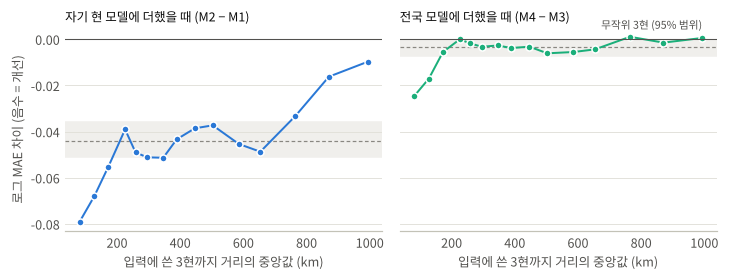

In [19]:
# 인구가 비슷한 현이라서 닮은 것은 아닌지: 거리와 상관없이 인구가 가장 비슷한 3현
wp = nb_weights(info, 3, 'pop'); Ep = run(nb_w=wp)
ef = effect_table(Ep, PAIRS); ef = ef[ef['연도'] == '전체'].set_index('비교')
print('인구가 비슷한 3현 (거리 중앙값 %.0f km):' % np.median(Dn[wp.to_numpy() > 0])); display(ef.round(3))
for a, b in PAIRS:
    k = f'{a[:2]}{b[:2]}'; r = ef.loc[f'{a} - {b}']
    fx[f'pop_{k}'] = r['차이']; fx[f'pop_{k}_lo'] = r['하한']; fx[f'pop_{k}_hi'] = r['상한']
fx['pop_dist'] = np.median(Dn[wp.to_numpy() > 0])

NR = 200  # 무작위 반복 수. 한 번에 1초쯤 걸림
rnd = []
for seed in range(NR):
    E = run(nb_w=nb_weights(info, 3, 'random', seed=seed))
    rnd.append({'seed': seed, 'M2-M1': log_mae(E, M2) - log_mae(E, M1), 'M4-M3': log_mae(E, M4) - log_mae(E, M3),
                **{f'M2-M1 {Y}': log_mae(E[E.eval_year == Y], M2) - log_mae(E[E.eval_year == Y], M1) for Y in (2021, 2022, 2023)},
                **{f'M4-M3 {Y}': log_mae(E[E.eval_year == Y], M4) - log_mae(E[E.eval_year == Y], M3) for Y in (2021, 2022, 2023)}})
RD = pd.DataFrame(rnd); save(RD, 'neighbor_random.csv')
facts('neighbor', {'island_changed': island_changed, **fx, 'rand_neg_M4M3': int((RD['M4-M3'] < 0).sum())})
base = {'M2-M1': log_mae(E3, M2) - log_mae(E3, M1), 'M4-M3': log_mae(E3, M4) - log_mae(E3, M3)}
for k in ('M2-M1', 'M4-M3'):
    q = RD[k].quantile([0.025, 0.5, 0.975])
    print('%s | 가까운 3현 %.3f | 무작위 3현 중앙값 %.3f [%.3f, %.3f] | 무작위가 가까운 3현보다 나은 횟수 %d/%d' % (
        k, base[k], q[0.5], q[0.025], q[0.975], int((RD[k] <= base[k]).sum()), NR))
for Y in (2021, 2022, 2023):
    d = E3[E3.eval_year == Y]
    print(Y, '| M4-M3 가까운 3현 %.3f, 무작위 중앙값 %.3f [%.3f, %.3f]' % (log_mae(d, M4) - log_mae(d, M3), *RD[f'M4-M3 {Y}'].quantile([0.5, 0.025, 0.975])))

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.6), sharey=True)
for ax, k, ttl in ((axes[0], 'M2-M1', '자기 현 모델에 더했을 때 (M2 − M1)'), (axes[1], 'M4-M3', '전국 모델에 더했을 때 (M4 − M3)')):
    lo, hi = RD[k].quantile([0.025, 0.975])
    ax.axhspan(lo, hi, color='#f0efec', zorder=0)
    ax.axhline(RD[k].median(), color=MUTED, linewidth=0.8, linestyle=(0, (3, 2)))
    dot(ax, RK['거리 중앙값(km)'], RK[k + ' 전체'], B1 if k == 'M2-M1' else B3)
    ax.axhline(0, color=INK2, linewidth=0.7); clean(ax); ax.set_title(ttl, fontsize=8.2, pad=4); ax.set_xlabel('입력에 쓴 3현까지 거리의 중앙값 (km)')
axes[0].set_ylabel('로그 MAE 차이 (음수 = 개선)')
axes[1].text(RK['거리 중앙값(km)'].max(), RD['M4-M3'].quantile(0.975) + 0.004, '무작위 3현 (95% 범위)', fontsize=7, color=INK2, ha='right', va='bottom')
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig8_distance.png'); plt.show()

### 6.3 보고 지연 1주, 2주 (표 9)

자기 현 값은 그대로 두고 인근 현과 전국 합계만 늦춘다.

In [20]:
E0 = evaluate_years(build_panel(W, yw, info), W, yw)
base = {m: log_mae(E0, m) for m in (M1, M2, M3, M4)}

In [21]:
# 자기 현 값은 예측 시점까지 안다고 두고, 다른 현에서 오는 값만 늦춤
rows = []
for lag in (0, 1, 2):
    Pd = build_panel(W, yw, info, nb_lag=lag, nat_lag=lag); E = evaluate_years(Pd, W, yw)
    ef = effect_table(E, [(M2, M1), (M3, M1), (M4, M1), (M4, M3)]).set_index(['비교', '연도'])
    # M1은 다른 현의 값을 안 쓰지만, 지연을 주면 자료 맨 앞의 학습 행이 47행씩 줄어서 넷째 자리가 달라짐. 차이는 같은 학습 행끼리 구함
    r = {'지연(주)': lag, 'M1': log_mae(E, M1), '학습 행(2021년 평가)': len(train_rows(Pd, yw, 2021))}
    for m in (M2, M3, M4):
        r[m[:2]] = log_mae(E, m)
        r[m[:2] + ' 개선분 유지율'] = (base[M1] - log_mae(E, m)) / (base[M1] - base[m])
    for a, b in ((M2, M1), (M4, M3)):
        k = f'{a} - {b}'
        r[f'{a[:2]}-{b[:2]}'] = ef.loc[(k, '전체'), '차이']; r[f'{a[:2]}-{b[:2]} 하한'] = ef.loc[(k, '전체'), '하한']; r[f'{a[:2]}-{b[:2]} 상한'] = ef.loc[(k, '전체'), '상한']
        for Y in (2021, 2022, 2023): r[f'{a[:2]}-{b[:2]} {Y}'] = ef.loc[(k, Y), '차이']
    rows.append(r)
T10 = pd.DataFrame(rows); save(T10, 'delay.csv'); display(T10.round(3))
print('M1(지연 없음): %.4f' % base[M1])

,지연(주),M1,학습 행(2021년 평가),M2,M2 개선분 유지율,M3,M3 개선분 유지율,M4,M4 개선분 유지율,M2-M1,...,M2-M1 상한,M2-M1 2021,M2-M1 2022,M2-M1 2023,M4-M3,M4-M3 하한,M4-M3 상한,M4-M3 2021,M4-M3 2022,M4-M3 2023
0,0,0.818,19270,0.739,1.000,0.756,1.000,0.731,1.000,-0.079,...,-0.066,-0.096,-0.019,-0.123,-0.025,-0.034,-0.016,-0.049,-0.003,-0.022
1,1,0.818,19223,0.748,0.881,0.765,0.852,0.744,0.847,-0.070,...,-0.060,-0.088,-0.019,-0.102,-0.021,-0.029,-0.013,-0.044,-0.002,-0.016
2,2,0.818,19176,0.760,0.733,0.771,0.756,0.757,0.697,-0.058,...,-0.050,-0.069,-0.018,-0.088,-0.013,-0.021,-0.006,-0.031,-0.000,-0.009


M1(지연 없음): 0.8182


In [22]:
# 인근만 늦고 전국 합계는 제때 들어오는 경우도 확인 (중간보고서 5.5절과 같은 가정)
for lag in (1, 2):
    E = evaluate_years(build_panel(W, yw, info, nb_lag=lag), W, yw)
    print('인근만 %d주 지연: M2 %.3f (유지율 %.0f%%), M4 %.3f' % (lag, log_mae(E, M2), 100 * (base[M1] - log_mae(E, M2)) / (base[M1] - base[M2]), log_mae(E, M4)))

인근만 1주 지연: M2 0.748 (유지율 88%), M4 0.730


인근만 2주 지연: M2 0.760 (유지율 73%), M4 0.732


### 6.4 그래디언트 부스팅 (표 10)

입력, 평가 행, 학습 구간은 그대로 두고 회귀 모델만 바꾼다. 설정값은 주제를 정할 때 쓰던 값 그대로이고, 마지막 셀에서 설정을 바꿔도 결론이 같은지 본다. 유행 단계와 정점 순서에 따른 차이도 부스팅으로 다시 계산한다. 마지막 셀은 계산 잡음 확인이다. 인근 입력에 아주 작은 잡음을 더해 10번 다시 돌리고 결과가 얼마나 흔들리는지 본다.

In [23]:
P = build_panel(W, yw, info)
PAIRS = [(M2, M1), (M3, M1), (M4, M3), (M2, M3)]

def hgb(lr=0.05, it=300, leaf=31):
    # 학습률과 반복 수는 주제 정할 때 시험 삼아 쓰던 값 그대로. 이번 결과를 보고 바꾸지 않음. 조기 종료를 켜면 검증용 행을 무작위로 떼어 내서 결과가 흔들림
    return lambda: HistGradientBoostingRegressor(learning_rate=lr, max_iter=it, max_leaf_nodes=leaf, early_stopping=False, random_state=0)

ER = evaluate_years(P, W, yw)
EG = evaluate_years(P, W, yw, learner=hgb())
names = [M0, M1, M2, M3, M4]
rows = []
for Y in (2021, 2022, 2023, '전체'):
    d = EG if Y == '전체' else EG[EG.eval_year == Y]
    rows += [{'연도': str(Y), '모델': nm, **metrics(d, 'pred_' + nm).to_dict()} for nm in names]
TG = pd.DataFrame(rows); save(TG, 'boosting_metrics.csv')
display(TG.pivot(index='모델', columns='연도', values='logMAE').loc[names, ['2021', '2022', '2023', '전체']].round(3))
display(TG.pivot(index='모델', columns='연도', values='RMSE').loc[names, ['2021', '2022', '2023', '전체']].round(1))
CG = effect_table(EG, PAIRS); save(CG, 'boosting_effects.csv'); display(CG.round(3))

연도,2021,2022,2023,전체
모델,,,,
M0 현재값 유지,0.917,0.771,0.805,0.831
M1 자기 현 이력,0.902,0.714,0.676,0.764
M2 인근 3현 추가,0.852,0.683,0.585,0.707
M3 전국 추가,0.906,0.687,0.568,0.720
M4 인근과 전국 추가,0.861,0.668,0.550,0.693


연도,2021,2022,2023,전체
모델,,,,
M0 현재값 유지,162.6,89.4,77.4,116.1
M1 자기 현 이력,141.2,64.7,61.9,96.6
M2 인근 3현 추가,137.7,64.0,55.5,93.3
M3 전국 추가,150.5,65.6,61.4,101.2
M4 인근과 전국 추가,142.2,64.9,53.9,95.4


,연도,비교,차이,하한,상한
0,2021,M2 인근 3현 추가 - M1 자기 현 이력,-0.050,-0.067,-0.033
1,2021,M3 전국 추가 - M1 자기 현 이력,0.003,-0.017,0.025
2,2021,M4 인근과 전국 추가 - M3 전국 추가,-0.045,-0.057,-0.033
3,2021,M2 인근 3현 추가 - M3 전국 추가,-0.053,-0.076,-0.030
4,2022,M2 인근 3현 추가 - M1 자기 현 이력,-0.030,-0.055,-0.007
5,2022,M3 전국 추가 - M1 자기 현 이력,-0.027,-0.052,-0.001
6,2022,M4 인근과 전국 추가 - M3 전국 추가,-0.019,-0.031,-0.008
7,2022,M2 인근 3현 추가 - M3 전국 추가,-0.004,-0.028,0.021
8,2023,M2 인근 3현 추가 - M1 자기 현 이력,-0.090,-0.109,-0.073
9,2023,M3 전국 추가 - M1 자기 현 이력,-0.107,-0.124,-0.092


In [24]:
# 같은 입력에서 릿지와 부스팅 중 어느 쪽 오차가 작은지
EG2 = EG.rename(columns={'pred_' + m: 'pred_부스팅 ' + m for m in (M1, M2, M3, M4)})
for m in (M1, M2, M3, M4): EG2['pred_릿지 ' + m] = ER['pred_' + m].to_numpy()
BR = effect_table(EG2, [('부스팅 ' + m, '릿지 ' + m) for m in (M1, M2, M3, M4)]); save(BR, 'boosting_vs_ridge.csv')
display(BR.query("연도 == '전체'").round(3))

,연도,비교,차이,하한,상한
12,전체,부스팅 M1 자기 현 이력 - 릿지 M1 자기 현 이력,-0.054,-0.071,-0.037
13,전체,부스팅 M2 인근 3현 추가 - 릿지 M2 인근 3현 추가,-0.032,-0.045,-0.019
14,전체,부스팅 M3 전국 추가 - 릿지 M3 전국 추가,-0.035,-0.049,-0.022
15,전체,부스팅 M4 인근과 전국 추가 - 릿지 M4 인근과 전국 추가,-0.038,-0.050,-0.026


In [25]:
# 2022년 세 현의 정점 직후 예측 (6.1절과 같은 15행)
ratio = lambda d, m: float(np.exp((np.log1p(d['pred_' + m]) - np.log1p(d.y_tgt)).mean()))
pick = lambda E: E[(E.eval_year == 2022) & E.pref.isin(['Osaka', 'Aichi', 'Hyogo']) & E.o_week.between(27, 31)]
print('세 현 15행 예측/실제 | 릿지 M1 %.2f, M2 %.2f | 부스팅 M1 %.2f, M2 %.2f' % (ratio(pick(ER), M1), ratio(pick(ER), M2), ratio(pick(EG), M1), ratio(pick(EG), M2)))
display(pick(EG)[['pref', 'o_week', 'y_now', 'y_tgt', 'pred_' + M1, 'pred_' + M2]].round(0))
rm22 = lambda E, m: np.sqrt(((E[E.eval_year == 2022]['pred_' + m] - E[E.eval_year == 2022].y_tgt)**2).mean())
fb = {'ratio_ridge_M1': ratio(pick(ER), M1), 'ratio_ridge_M2': ratio(pick(ER), M2), 'ratio_hgb_M1': ratio(pick(EG), M1), 'ratio_hgb_M2': ratio(pick(EG), M2),
      'rmse22_ridge_M1': rm22(ER, M1), 'rmse22_ridge_M2': rm22(ER, M2), 'rmse22_hgb_M1': rm22(EG, M1), 'rmse22_hgb_M2': rm22(EG, M2)}

세 현 15행 예측/실제 | 릿지 M1 2.05, M2 2.87 | 부스팅 M1 1.00, M2 1.44


,pref,o_week,y_now,y_tgt,pred_M1 자기 현 이력,pred_M2 인근 3현 추가
2282,Aichi,27,796,477.0,505.0,649.0
2283,Aichi,28,1097,307.0,295.0,564.0
2284,Aichi,29,916,162.0,273.0,445.0
2285,Aichi,30,769,84.0,246.0,367.0
2286,Aichi,31,477,76.0,115.0,178.0
2858,Hyogo,27,327,683.0,469.0,595.0
2859,Hyogo,28,675,439.0,454.0,595.0
2860,Hyogo,29,694,344.0,370.0,608.0
2861,Hyogo,30,733,268.0,395.0,439.0
2862,Hyogo,31,683,283.0,418.0,375.0


In [26]:
# 유행 단계별 (5.4절과 같은 기준)
EG['phase'] = np.where(EG.y_tgt > EG.y_now * 1.2, '상승', np.where(EG.y_tgt < EG.y_now / 1.2, '하강', '정체'))
ph = EG.groupby(['phase', 'eval_year']).apply(lambda x: pd.Series({'행 수': len(x), 'M1': log_mae(x, M1), 'M2': log_mae(x, M2)}), include_groups=False)
display(ph.round(3).unstack('eval_year').swaplevel(axis=1).sort_index(axis=1).loc[['상승', '하강', '정체']]); save(ph.reset_index(), 'boosting_phase.csv')

eval_year   2021                 2022                 2023               
              M1     M2    행 수     M1     M2    행 수     M1     M2     행 수
phase                                                                    
상승         1.189  1.046  954.0  0.818  0.734  893.0  0.845  0.688   862.0
하강         0.809  0.806  855.0  0.707  0.720  944.0  0.614  0.550  1077.0
정체         0.470  0.528  447.0  0.505  0.492  419.0  0.425  0.428   317.0

In [27]:
# 정점 순서에 따른 차이도 부스팅에서 다시 (6.1절과 같은 계산)
LG = peak_lead(EG, W, yw, info)
rows = []
for k in ('인근이 1주 넘게 먼저', '차이 1주 이내', '자기 현이 1주 넘게 먼저'):
    d = LG[LG['구분'] == k]; pt, lo, hi = boot_mean(d['절대 오차 차이'], d.pref)
    rows.append({'구분': k, '현×연도': len(d), 'M1 편향': d['M1 편향'].mean(), 'M2 편향': d['M2 편향'].mean(), '절대 오차 차이': pt, '하한': lo, '상한': hi})
TL = pd.DataFrame(rows); display(TL.round(3)); save(TL, 'boosting_lead_groups.csv')
fb['lead_rho_abs'] = spearmanr(LG['인근 정점 − 자기 정점'], LG['절대 오차 차이'])[0]; fb['lead_bias_M1'] = LG['M1 편향'].mean(); fb['lead_bias_M2'] = LG['M2 편향'].mean()
print('정점 순서와 절대 오차 차이의 순위 상관 %.2f | 정점 전후 편향 M1 %.2f, M2 %.2f' % (fb['lead_rho_abs'], fb['lead_bias_M1'], fb['lead_bias_M2']))
facts('boosting', fb)

,구분,현×연도,M1 편향,M2 편향,절대 오차 차이,하한,상한
0,인근이 1주 넘게 먼저,57,0.485,0.394,-0.052,-0.090,-0.014
1,차이 1주 이내,35,0.550,0.473,-0.042,-0.080,-0.000
2,자기 현이 1주 넘게 먼저,47,0.326,0.384,0.040,-0.008,0.090


정점 순서와 절대 오차 차이의 순위 상관 0.19 | 정점 전후 편향 M1 0.45, M2 0.41


In [28]:
# 설정을 바꿔도 결론이 같은지
rows = []
for lr, it, leaf in ((0.05, 300, 31), (0.05, 100, 31), (0.1, 300, 31), (0.05, 300, 15), (0.05, 300, 63)):
    E = EG if (lr, it, leaf) == (0.05, 300, 31) else evaluate_years(P, W, yw, learner=hgb(lr, it, leaf))
    rows.append({'학습률': lr, '반복': it, '잎 수': leaf, **{m[:2]: log_mae(E, m) for m in (M1, M2, M3, M4)},
                 'M2-M1': log_mae(E, M2) - log_mae(E, M1), 'M4-M3': log_mae(E, M4) - log_mae(E, M3),
                 **{f'M4-M3 {Y}': log_mae(E[E.eval_year == Y], M4) - log_mae(E[E.eval_year == Y], M3) for Y in (2021, 2022, 2023)}})
HS = pd.DataFrame(rows); save(HS, 'boosting_settings.csv'); display(HS.round(3))

,학습률,반복,잎 수,M1,M2,M3,M4,M2-M1,M4-M3,M4-M3 2021,M4-M3 2022,M4-M3 2023
0,0.05,300,31,0.764,0.707,0.720,0.693,-0.057,-0.027,-0.045,-0.019,-0.018
1,0.05,100,31,0.761,0.705,0.713,0.693,-0.056,-0.021,-0.028,-0.013,-0.020
2,0.10,300,31,0.773,0.713,0.728,0.706,-0.060,-0.022,-0.026,-0.025,-0.014
3,0.05,300,15,0.761,0.702,0.713,0.693,-0.060,-0.019,-0.038,-0.010,-0.010
4,0.05,300,63,0.771,0.715,0.730,0.705,-0.056,-0.025,-0.039,-0.022,-0.013


In [29]:
# 부스팅은 입력을 구간으로 나눠 쓰기 때문에 끝자리가 조금만 달라도 경계가 바뀌고 결과가 흔들림 (인근 평균을 더하는 순서만 바꿔도 셋째 자리가 달라졌음)
# 인근 입력에 1e-12 크기의 잡음을 더해 10번 다시 돌려서 그 폭을 봄. M1, M3는 인근 입력이 없어서 그대로
def phase_gap(E, g, Y):
    d = E[(E.phase == g) & (E.eval_year == Y)]
    return log_mae(d, M2) - log_mae(d, M1)

rows = []
for seed in range(10):
    Pn = P.copy(); Pn[NB] = Pn[NB] + np.random.default_rng(seed).normal(0, 1e-12, (len(Pn), len(NB)))
    En = evaluate_years(Pn, W, yw, models={M2: MODELS[M2], M4: MODELS[M4]}, learner=hgb())
    for m in (M1, M3): En['pred_' + m] = EG['pred_' + m].to_numpy()
    En['phase'] = EG.phase.to_numpy()
    r = {'seed': seed, 'M2': log_mae(En, M2), 'M4': log_mae(En, M4)}
    r['M2-M1'], _, r['M2-M1 상한'] = cluster_boot_diff(En, 'pred_' + M2, 'pred_' + M1)
    r['M4-M3'], _, r['M4-M3 상한'] = cluster_boot_diff(En, 'pred_' + M4, 'pred_' + M3)
    r['M4-M3 2022'], r['M4-M3 2022 하한'], r['M4-M3 2022 상한'] = cluster_boot_diff(En[En.eval_year == 2022], 'pred_' + M4, 'pred_' + M3)
    r['2022 RMSE M2'] = rm22(En, M2); r['세 현 예측/실제 M2'] = ratio(pick(En), M2)
    for Y in (2021, 2022, 2023): r[f'하강 {Y}'] = phase_gap(En, '하강', Y)
    r['상승 최대'] = max(phase_gap(En, '상승', Y) for Y in (2021, 2022, 2023))
    Ln = peak_lead(En, W, yw, info); r['정점 전후 M2 편향'] = Ln['M2 편향'].mean()
    for k, nm in (('인근이 1주 넘게 먼저', '인근 먼저'), ('자기 현이 1주 넘게 먼저', '자기 먼저')):
        d = Ln[Ln['구분'] == k]; r[nm], r[nm + ' 하한'], r[nm + ' 상한'] = boot_mean(d['절대 오차 차이'], d.pref)
    rows.append(r)
NZ = pd.DataFrame(rows); save(NZ, 'boosting_noise.csv'); display(NZ.drop(columns='seed').agg(['min', 'max']).T.round(3))

,min,max
M2,0.702,0.708
M4,0.691,0.696
M2-M1,-0.061,-0.056
M2-M1 상한,-0.048,-0.043
M4-M3,-0.029,-0.025
M4-M3 상한,-0.023,-0.018
M4-M3 2022,-0.022,-0.016
M4-M3 2022 하한,-0.034,-0.027
M4-M3 2022 상한,-0.011,-0.005
2022 RMSE M2,63.318,64.162


### 6.5 유행 시기 오차 (표 11)

4주 앞 예측값을 목표 주 순서로 이은 곡선과 실제 곡선에서 무게중심, 유행 시작 주, 최고 주를 각각 재고 차이를 본다. 시작 주를 정하는 기준을 바꿨을 때의 결과도 함께 본다.

In [30]:
E = evaluate_years(build_panel(W, yw, info), W, yw)
names = [M0, M1, M2, M3, M4]

def onset(w, v, thr):
    # 기준 이상인 주가 2주 이어지는 첫 주. 한 주만 튀는 값에 걸리지 않게
    ok = v >= thr
    hit = np.where(ok[:-1] & ok[1:])[0]
    return w[hit[0]] if len(hit) else np.nan

rows = []
for (Y, p), d in E.groupby(['eval_year', 'pref']):
    d = d.sort_values('t_week'); w = d.t_week.to_numpy(); y = d.y_tgt.to_numpy()
    thr = 0.25 * y.max()  # 목표 주 5~52주 안에서 실제 최댓값의 25%. 예측 곡선에도 같은 기준을 씀 (사후 평가용)
    r = {'연도': Y, 'pref': p, '실제 무게중심': (w * y).sum() / y.sum(), '실제 시작 주': onset(w, y, thr), '실제 최고 주': w[y.argmax()]}
    for nm in names:
        v = d['pred_' + nm].to_numpy()
        r['무게중심 ' + nm] = (w * v).sum() / v.sum() - r['실제 무게중심']
        r['시작 주 ' + nm] = onset(w, v, thr) - r['실제 시작 주']
        r['최고 주 ' + nm] = w[v.argmax()] - r['실제 최고 주']
    rows.append(r)
TM = pd.DataFrame(rows)
print('목표 주 범위:', int(E.t_week.min()), '~', int(E.t_week.max()), '| 현×연도', len(TM))
cut = TM['실제 시작 주'] == E.t_week.min()
print('실제 시작 주가 첫 목표 주(5주)에 걸린 경우:', int(cut.sum()), '| 예측 곡선이 기준에 못 미친 경우:', {nm[:2]: int(TM['시작 주 ' + nm].isna().sum()) for nm in names})
# 연초에 이미 기준을 넘어 있던 현은 시작 시기를 잴 수 없어서 시작 주 비교에서 뺌
TM.loc[cut, [c_ for c_ in TM.columns if c_.startswith('시작 주 ')]] = np.nan
save(TM, 'timing_by_pref.csv')

def boot(a, b, B=2000, seed=0):
    # 현마다 세 해가 있으므로 현 단위로 뽑음
    g = pd.DataFrame({'p': TM.pref, 'd': TM[a].abs() - TM[b].abs()}).dropna().groupby('p').d.agg(['sum', 'count'])
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(B, len(g)))
    s = g['sum'].to_numpy()[idx].sum(1) / g['count'].to_numpy()[idx].sum(1)
    return g['sum'].sum() / g['count'].sum(), np.quantile(s, 0.025), np.quantile(s, 0.975)

rows = []
for kind in ('무게중심', '시작 주', '최고 주'):
    for nm in names:
        col = f'{kind} {nm}'
        r = {'지표': kind, '모델': nm, **{str(Y): TM.loc[TM['연도'] == Y, col].abs().mean() for Y in (2021, 2022, 2023)},
             '전체': TM[col].abs().mean(), '평균 부호 오차': TM[col].mean(), '현×연도': int(TM[col].notna().sum())}
        rows.append(r)
T12 = pd.DataFrame(rows); save(T12, 'timing_summary.csv'); display(T12.round(2))
rows = []
for kind in ('무게중심', '시작 주', '최고 주'):
    for a, b in ((M2, M1), (M4, M3), (M2, M0)):
        pt, lo, hi = boot(f'{kind} {a}', f'{kind} {b}')
        print('%s 절대 오차 차이 %s − %s: %.2f주 [%.2f, %.2f]' % (kind, a[:2], b[:2], pt, lo, hi))
        rows.append({'지표': kind, '비교': f'{a[:2]}-{b[:2]}', '차이': pt, '하한': lo, '상한': hi})
save(pd.DataFrame(rows), 'timing_diff.csv')

목표 주 범위: 5 ~ 52 | 현×연도 141
실제 시작 주가 첫 목표 주(5주)에 걸린 경우: 16 | 예측 곡선이 기준에 못 미친 경우: {'M0': 0, 'M1': 0, 'M2': 0, 'M3': 0, 'M4': 0}


,지표,모델,2021,2022,2023,전체,평균 부호 오차,현×연도
0,무게중심,M0 현재값 유지,3.36,2.92,3.34,3.21,2.74,141
1,무게중심,M1 자기 현 이력,3.98,1.65,3.65,3.09,2.98,141
2,무게중심,M2 인근 3현 추가,3.10,1.62,2.82,2.51,2.19,141
3,무게중심,M3 전국 추가,3.42,1.59,2.74,2.58,2.22,141
4,무게중심,M4 인근과 전국 추가,3.07,1.56,2.68,2.44,2.09,141
5,시작 주,M0 현재값 유지,4.98,4.56,4.00,4.52,3.22,125
6,시작 주,M1 자기 현 이력,4.82,2.82,4.64,4.14,3.99,125
7,시작 주,M2 인근 3현 추가,4.25,4.03,4.14,4.14,3.01,125
8,시작 주,M3 전국 추가,3.91,2.95,3.98,3.63,3.20,125
9,시작 주,M4 인근과 전국 추가,3.75,3.74,4.00,3.83,2.55,125


무게중심 절대 오차 차이 M2 − M1: -0.58주 [-0.72, -0.44]
무게중심 절대 오차 차이 M4 − M3: -0.14주 [-0.24, -0.05]
무게중심 절대 오차 차이 M2 − M0: -0.70주 [-0.87, -0.52]
시작 주 절대 오차 차이 M2 − M1: 0.01주 [-0.59, 0.77]
시작 주 절대 오차 차이 M4 − M3: 0.20주 [-0.31, 0.94]
시작 주 절대 오차 차이 M2 − M0: -0.38주 [-0.95, 0.20]
최고 주 절대 오차 차이 M2 − M1: -0.58주 [-1.34, 0.11]
최고 주 절대 오차 차이 M4 − M3: 0.22주 [-0.43, 1.00]
최고 주 절대 오차 차이 M2 − M0: -0.97주 [-1.72, -0.36]


In [31]:
# 시작 주 기준(최댓값의 25%)은 임의로 정한 값이라 10%, 50%로도 확인. 연초에 기준을 넘어 있던 조합을 빼지 않았을 때도 같이 봄
def onset_err(q, drop_cut=True):
    rows = []
    for (Y, p), d in E.groupby(['eval_year', 'pref']):
        d = d.sort_values('t_week'); w = d.t_week.to_numpy(); y = d.y_tgt.to_numpy(); thr = q * y.max(); a = onset(w, y, thr)
        if drop_cut and a == w[0]: continue
        rows.append({'연도': Y, 'pref': p, **{nm: onset(w, d['pred_' + nm].to_numpy(), thr) - a for nm in names}})
    return pd.DataFrame(rows)

rows = []
for q, drop in ((0.10, True), (0.25, True), (0.50, True), (0.25, False)):
    T = onset_err(q, drop); v = (T[M2].abs() - T[M1].abs()).dropna()
    g = pd.DataFrame({'p': T.pref[v.index], 'd': v}).groupby('p').d.agg(['sum', 'count'])
    idx = np.random.default_rng(0).integers(0, len(g), size=(2000, len(g)))
    bs = g['sum'].to_numpy()[idx].sum(1) / g['count'].to_numpy()[idx].sum(1)
    rows.append({'기준': f'{q:.0%}', '연초 조합': '제외' if drop else '포함', '현×연도': len(v), **{nm[:2]: T.loc[v.index, nm].abs().mean() for nm in (M0, M1, M2)},
                 'M2-M1': v.mean(), '하한': np.quantile(bs, 0.025), '상한': np.quantile(bs, 0.975)})
OS = pd.DataFrame(rows); save(OS, 'timing_onset_sens.csv'); display(OS.round(2))

,기준,연초 조합,현×연도,M0,M1,M2,M2-M1,하한,상한
0,10%,제외,113,4.71,4.73,4.28,-0.44,-1.03,0.13
1,25%,제외,125,4.52,4.14,4.14,0.01,-0.59,0.77
2,50%,제외,130,4.63,4.41,3.74,-0.67,-1.46,-0.02
3,25%,포함,141,4.16,4.02,4.18,0.16,-0.45,0.88


In [32]:
# 현 사이에 유행 시기가 얼마나 흩어졌는지 (실제 무게중심의 사분위 범위)
iqr = TM.groupby('연도')['실제 무게중심'].agg(lambda v: v.quantile(0.75) - v.quantile(0.25))
print('현별 실제 무게중심의 사분위 범위(주):', iqr.round(1).to_dict())
facts('timing', {'n': len(TM), 'onset_cut': int(cut.sum()), **{f'iqr_{Y}': iqr[Y] for Y in (2021, 2022, 2023)}})

현별 실제 무게중심의 사분위 범위(주): {2021: 5.4, 2022: 6.8, 2023: 2.8}


### 6.6~6.7 특이 관측, 기준 모델, 설정 (표 12, 13, 14, 15)

오키나와, 2020년 코로나 유행기 행, 보고 수가 아주 작은 행을 하나씩 빼고 다시 계산한다. 계절 입력을 네 모델에서 빼서 기준 모델을 강화했을 때의 결과(6.7절)도 여기서 구한다. 현 단위 대신 주 묶음으로 다시 뽑은 구간(묶음 길이 4, 8, 13, 26주)도 구하고, 릿지의 α, 예측 기간, 단계 구분 기준도 바꿔 본다. 예측 시점의 보고 수 구간별 차이와 현별로 나아진 현의 수도 여기 있다. 표 14의 나머지 두 행은 6.1절과 6.4절에서 나온 값이다. 표 15는 자기 현의 이력과 전국 입력을 늘린 더 강한 기준에서 같은 비교를 한 것이고(릿지와 부스팅), 무작위 3현 30번도 함께 구한다. 릿지는 이 기준으로 2015~2023년을 모두 평가해 연도별 차이도 저장한다. 끝으로 인근 현의 수, α, 계절 입력 여부를 평가 연도 이전의 자료만으로 골라 다시 평가한다(검증에서 2020년을 뺀 것도 함께). 1분 반쯤 걸린다.

In [33]:
P = build_panel(W, yw, info)
PAIRS = [(M2, M1), (M4, M3)]

def line(label, E, n_train=None):
    ef = effect_table(E, PAIRS).set_index(['비교', '연도'])
    r = {'조건': label, '평가 행': len(E), **{m[:2]: log_mae(E, m) for m in (M1, M2, M3, M4)}}
    for a, b in PAIRS:
        k = f'{a} - {b}'; s = f'{a[:2]}-{b[:2]}'
        r[s] = ef.loc[(k, '전체'), '차이']; r[s + ' 하한'] = ef.loc[(k, '전체'), '하한']; r[s + ' 상한'] = ef.loc[(k, '전체'), '상한']
        for Y in (2021, 2022, 2023): r[f'{s} {Y}'] = ef.loc[(k, Y), '차이']
    return r

E0 = evaluate_years(P, W, yw)
rows = [line('기본 설계', E0)]

In [34]:
# 오키나와: 인근 3현이 모두 657 km 넘게 떨어져 있고 코로나 전에도 여름에 유행함. 자료에서 통째로 빼고 다시 계산
keep = [p for p in W.columns if p != 'Okinawa']
rows.append(line('오키나와 제외', evaluate_years(build_panel(W[keep], yw, info.loc[keep]), W[keep], yw)))

In [35]:
# 코로나 유행기: 그 구간의 행을 학습에서 뺌 (예측 시점이나 목표 시점이 구간에 들면 제외)
# 구간은 자료로 먼저 잡음. 전국 합계가 2013~2019년 최솟값보다 낮았던 2020년 주의 처음부터 끝까지
nat = W.sum(axis=1); floor = nat[yw.index[yw.year <= 2019]].min()
low = yw[(yw.year == 2020) & (nat < floor)].week
print('전국 합계가 2013~2019년 최솟값(%d건)보다 낮았던 2020년 주: %d~%d주 중 %d주' % (floor, low.min(), low.max(), len(low)))
out_of = lambda ts: (lambda tr: ~(tr.time.isin(ts) | tr.t_time.isin(ts)))
cov0 = set(yw.index[(yw.year == 2020) & yw.week.between(low.min(), low.max())])
rows.append(line(f'2020년 {low.min()}~{low.max()}주의 행을 학습에서 제외', evaluate_years(P, W, yw, keep=out_of(cov0))))
# 더 넓게: 전국 휴교 요청 직후인 2020년 10주부터 그해 말까지
cov = set(yw.index[(yw.year == 2020) & (yw.week >= 10)])
no_cov = out_of(cov)
n_all = len(train_rows(P, yw, 2023)); n_cut = int(no_cov(train_rows(P, yw, 2023)).sum())
print('2023년 평가용 학습 행: %d → %d' % (n_all, n_cut))
rows.append(line('2020년 10주 이후 2020년 행을 학습에서 제외', evaluate_years(P, W, yw, keep=no_cov)))
# 유행이 다시 커지기 전인 2021년 26주까지 넓혀도 같은지
cov2 = cov | set(yw.index[(yw.year == 2021) & (yw.week <= 26)])
rows.append(line('2020년 10주부터 2021년 26주까지의 행을 학습에서 제외', evaluate_years(P, W, yw, keep=out_of(cov2))))

전국 합계가 2013~2019년 최솟값(221건)보다 낮았던 2020년 주: 17~40주 중 23주
2023년 평가용 학습 행: 24158 → 21902


In [36]:
# 보고 수가 아주 작은 행: 0건과 2건의 로그 차이가 1,000건과 3,000건의 차이와 같게 잡힘. 예측 시점 보고 수 5건 미만을 평가에서 뺌
rows.append(line('예측 시점 보고 수 5건 미만 행을 평가에서 제외', E0[E0.y_now >= 5]))
rows.append(line('오사카, 아이치, 효고를 평가에서 제외', E0[~E0.pref.isin(['Osaka', 'Aichi', 'Hyogo'])]))

In [37]:
# 기준 모델 M1이 약해서 인근 정보의 이득이 크게 잡힌 것은 아닌지. M1은 세 해를 합쳐도 현재값 유지와 비슷했고, 코로나 전에 배운 계절 입력이 2021년 이후에는 오히려 해가 됨
# 계절 입력(sin, cos)을 네 모델에서 모두 빼고 같은 평가를 다시 함
OWN_NS = [c_ for c_ in OWN if c_ not in ('ws', 'wc')]
NS = {M1: OWN_NS, M2: OWN_NS + NB, M3: OWN_NS + NAT, M4: OWN_NS + NB + NAT}
ENS = evaluate_years(P, W, yw, models=NS)
rows.append(line('계절 입력을 네 모델에서 제외', ENS))
save(effect_table(ENS, PAIRS + [(M1, M0)]), 'noseason_effects.csv')
assert (ENS.time.to_numpy() == E0.time.to_numpy()).all() and (ENS.pref.to_numpy() == E0.pref.to_numpy()).all()
X = E0[['pref', 'y_tgt', 'eval_year']].copy(); X['a'] = E0['pred_' + M2].to_numpy(); X['b'] = ENS['pred_' + M1].to_numpy()
ns_fix = cluster_boot_diff(X, 'a', 'b')
print('고정 설계의 M2 − 계절 입력을 뺀 M1: %.3f [%.3f, %.3f]' % ns_fix)
nb22 = ENS[(ENS.eval_year == 2022) & (ENS.y_now >= 5)]; ns22 = cluster_boot_diff(nb22, 'pred_' + M2, 'pred_' + M1)
print('계절 입력 제외, 2022년 M2-M1 | 5건 이상 %d행: %.3f [%.3f, %.3f]' % (len(nb22), *ns22))
# 계절 입력을 뺀 모델에서도 전국 합계를 넘는 이득이 가까운 현에서만 나오는지 (무작위 3현 50번)
ns_rand = []
for seed in range(50):
    Er = evaluate_years(build_panel(W, yw, info, nb_w=nb_weights(info, 3, 'random', seed=seed)), W, yw, models=NS)
    ns_rand.append(log_mae(Er, M4) - log_mae(Er, M3))
print('계절 입력 제외, 무작위 3현 50번의 M4-M3: 중앙값 %.3f [%.3f, %.3f]' % tuple(np.quantile(ns_rand, [0.5, 0.025, 0.975])))

for a in (0.1, 10, 100):
    rows.append(line(f'릿지 α = {a:g}', evaluate_years(P, W, yw, alpha=a)))
T13 = pd.DataFrame(rows); save(T13, 'sensitivity.csv'); display(T13.round(3))

고정 설계의 M2 − 계절 입력을 뺀 M1: -0.006 [-0.019, 0.006]
계절 입력 제외, 2022년 M2-M1 | 5건 이상 1599행: -0.017 [-0.037, 0.003]


계절 입력 제외, 무작위 3현 50번의 M4-M3: 중앙값 -0.001 [-0.004, 0.002]


,조건,평가 행,M1,M2,M3,M4,M2-M1,M2-M1 하한,M2-M1 상한,M2-M1 2021,M2-M1 2022,M2-M1 2023,M4-M3,M4-M3 하한,M4-M3 상한,M4-M3 2021,M4-M3 2022,M4-M3 2023
0,기본 설계,6768,0.818,0.739,0.756,0.731,-0.079,-0.092,-0.066,-0.096,-0.019,-0.123,-0.025,-0.034,-0.016,-0.049,-0.003,-0.022
1,오키나와 제외,6624,0.830,0.747,0.763,0.739,-0.083,-0.097,-0.069,-0.102,-0.020,-0.127,-0.024,-0.033,-0.015,-0.047,-0.003,-0.023
2,2020년 17~40주의 행을 학습에서 제외,6768,0.824,0.748,0.752,0.732,-0.077,-0.089,-0.066,-0.094,-0.017,-0.120,-0.020,-0.028,-0.014,-0.037,-0.008,-0.016
3,2020년 10주 이후 2020년 행을 학습에서 제외,6768,0.828,0.756,0.764,0.744,-0.072,-0.085,-0.060,-0.086,-0.014,-0.117,-0.019,-0.026,-0.013,-0.037,-0.006,-0.016
4,2020년 10주부터 2021년 26주까지의 행을 학습에서 제외,6768,0.843,0.772,0.786,0.765,-0.070,-0.083,-0.058,-0.086,-0.007,-0.118,-0.020,-0.027,-0.014,-0.037,-0.009,-0.016
5,예측 시점 보고 수 5건 미만 행을 평가에서 제외,4975,0.809,0.726,0.750,0.720,-0.083,-0.100,-0.067,-0.112,-0.007,-0.126,-0.029,-0.041,-0.018,-0.065,-0.003,-0.021
6,"오사카, 아이치, 효고를 평가에서 제외",6336,0.817,0.741,0.752,0.732,-0.076,-0.089,-0.062,-0.089,-0.017,-0.121,-0.021,-0.030,-0.012,-0.044,0.000,-0.019
7,계절 입력을 네 모델에서 제외,6768,0.745,0.696,0.716,0.696,-0.049,-0.062,-0.036,-0.030,-0.031,-0.086,-0.020,-0.029,-0.012,-0.037,-0.006,-0.018
8,릿지 α = 0.1,6768,0.818,0.739,0.756,0.731,-0.079,-0.092,-0.066,-0.096,-0.019,-0.123,-0.025,-0.034,-0.016,-0.049,-0.003,-0.022
9,릿지 α = 10,6768,0.818,0.739,0.756,0.731,-0.079,-0.092,-0.067,-0.096,-0.019,-0.123,-0.025,-0.034,-0.016,-0.049,-0.003,-0.022


In [38]:
# 2022년의 M2-M1은 작은 보고 수 행을 빼면 어떻게 되는지 따로 확인
big = E0[(E0.y_now >= 5) & (E0.eval_year == 2022)]; sm = E0[(E0.y_now < 5) & (E0.eval_year == 2022)]
s22 = cluster_boot_diff(big, 'pred_' + M2, 'pred_' + M1)
print('2022년 M2-M1 | 5건 이상 %d행: %.3f [%.3f, %.3f] | 5건 미만 %d행: %.3f' % (len(big), *s22, len(sm), log_mae(sm, M2) - log_mae(sm, M1)))

2022년 M2-M1 | 5건 이상 1599행: -0.007 [-0.025, 0.010] | 5건 미만 657행: -0.046


In [39]:
# 주 묶음(8주) 부트스트랩. 현 단위 구간과 나란히 저장
rows = []
for a, b in PAIRS:
    for Y in (2021, 2022, 2023, '전체'):
        d = E0 if Y == '전체' else E0[E0.eval_year == Y]
        c1 = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b); c2 = block_boot_diff(d, 'pred_' + a, 'pred_' + b)
        rows.append({'비교': f'{a[:2]}-{b[:2]}', '연도': Y, '차이': c1[0], '현 하한': c1[1], '현 상한': c1[2], '주 묶음 하한': c2[1], '주 묶음 상한': c2[2]})
BB = pd.DataFrame(rows); save(BB, 'block_boot.csv'); display(BB.round(3))

,비교,연도,차이,현 하한,현 상한,주 묶음 하한,주 묶음 상한
0,M2-M1,2021,-0.096,-0.119,-0.071,-0.162,-0.033
1,M2-M1,2022,-0.019,-0.032,-0.006,-0.040,0.004
2,M2-M1,2023,-0.123,-0.137,-0.109,-0.182,-0.080
3,M2-M1,전체,-0.079,-0.092,-0.066,-0.117,-0.046
4,M4-M3,2021,-0.049,-0.064,-0.034,-0.070,-0.029
5,M4-M3,2022,-0.003,-0.016,0.009,-0.021,0.021
6,M4-M3,2023,-0.022,-0.032,-0.012,-0.031,-0.012
7,M4-M3,전체,-0.025,-0.034,-0.016,-0.038,-0.011


In [40]:
# 묶음 길이를 4주, 13주, 26주로 바꿔도 세 해 전체의 구간이 0 아래인지
rows = []
for a, b in PAIRS:
    for blk in (4, 8, 13, 26):
        pt, lo, hi = block_boot_diff(E0, 'pred_' + a, 'pred_' + b, block=blk)
        rows.append({'비교': f'{a[:2]}-{b[:2]}', '묶음(주)': blk, '차이': pt, '하한': lo, '상한': hi})
BL = pd.DataFrame(rows); save(BL, 'block_length.csv'); display(BL.round(3))

,비교,묶음(주),차이,하한,상한
0,M2-M1,4,-0.079,-0.108,-0.050
1,M2-M1,8,-0.079,-0.117,-0.046
2,M2-M1,13,-0.079,-0.116,-0.043
3,M2-M1,26,-0.079,-0.120,-0.037
4,M4-M3,4,-0.025,-0.036,-0.014
5,M4-M3,8,-0.025,-0.038,-0.011
6,M4-M3,13,-0.025,-0.039,-0.011
7,M4-M3,26,-0.025,-0.040,-0.010


In [41]:
# 예측 시점의 보고 수 구간별 M2 − M1. 2022년의 개선이 작은 보고 수 쪽에 몰렸는지, 세 해 전체도 그런지
e21 = (np.log1p(E0['pred_' + M2]) - np.log1p(E0.y_tgt)).abs() - (np.log1p(E0['pred_' + M1]) - np.log1p(E0.y_tgt)).abs()
BINS = {'0건': E0.y_now == 0, '1~4건': E0.y_now.between(1, 4), '5~19건': E0.y_now.between(5, 19), '20건 이상': E0.y_now >= 20}
CB = pd.DataFrame([{'연도': lab, '구간': k, '행 수': int((m & ym).sum()), 'M2-M1': e21[m & ym].mean()}
                   for lab, ym in (('2022', E0.eval_year == 2022), ('전체', E0.eval_year > 0)) for k, m in BINS.items()])
save(CB, 'count_bins.csv'); display(CB.round(3))

def group_gap(d, e, mask, key=None, B=2000, seed=0):
    # 두 집단의 차이의 구간. 같은 현(key를 주면 그 묶음)을 두 집단에서 함께 뽑음
    t = pd.DataFrame({'p': d.pref.to_numpy() if key is None else key, 'a': np.where(mask, e, np.nan), 'b': np.where(~mask, e, np.nan)}).groupby('p').agg(['sum', 'count'])
    idx = np.random.default_rng(seed).integers(0, len(t), size=(B, len(t))); full = np.arange(len(t))
    m = lambda k, i: t[(k, 'sum')].to_numpy()[i].sum(-1) / t[(k, 'count')].to_numpy()[i].sum(-1)
    dd = m('a', idx) - m('b', idx)
    return m('a', full) - m('b', full), np.quantile(dd, 0.025), np.quantile(dd, 0.975)

y22 = (E0.eval_year == 2022).to_numpy()
gap22 = group_gap(E0[y22], e21[y22].to_numpy(), (E0[y22].y_now < 5).to_numpy())
gap22b = group_gap(E0[y22], e21[y22].to_numpy(), (E0[y22].y_now < 5).to_numpy(), key=((E0[y22].o_week.astype(int) - 1) // 8).to_numpy())  # 8주 묶음은 2022년에 6개뿐
print('2022년 M2-M1, 5건 미만과 5건 이상의 차이: %.3f [%.3f, %.3f] | 주 묶음 [%.3f, %.3f]' % (*gap22, *gap22b[1:]))

,연도,구간,행 수,M2-M1
0,2022,0건,287,-0.044
1,2022,1~4건,370,-0.048
2,2022,5~19건,496,-0.024
3,2022,20건 이상,1103,0.000
4,전체,0건,780,-0.037
5,전체,1~4건,1013,-0.091
6,전체,5~19건,1439,-0.096
7,전체,20건 이상,3536,-0.078


2022년 M2-M1, 5건 미만과 5건 이상의 차이: -0.039 [-0.073, -0.007] | 주 묶음 [-0.123, 0.016]


In [42]:
# 현별로 보면 몇 개 현에서 나아졌는지
rows = []
for a, b in PAIRS:
    e = (np.log1p(E0['pred_' + a]) - np.log1p(E0.y_tgt)).abs() - (np.log1p(E0['pred_' + b]) - np.log1p(E0.y_tgt)).abs()
    for Y in (2021, 2022, 2023, '전체'):
        m = (E0.eval_year > 0) if Y == '전체' else (E0.eval_year == Y)
        bp = e[m].groupby(E0.pref[m].to_numpy()).mean()
        rows.append({'비교': f'{a[:2]}-{b[:2]}', '연도': Y, '나아진 현': int((bp < 0).sum()), '현 수': len(bp), '최소': bp.min(), '중앙값': bp.median(), '최대': bp.max()})
PS = pd.DataFrame(rows); save(PS, 'pref_share.csv'); display(PS.round(3))

,비교,연도,나아진 현,현 수,최소,중앙값,최대
0,M2-M1,2021,41,47,-0.277,-0.103,0.106
1,M2-M1,2022,28,47,-0.135,-0.017,0.067
2,M2-M1,2023,47,47,-0.224,-0.120,-0.029
3,M2-M1,전체,45,47,-0.157,-0.082,0.003
4,M4-M3,2021,38,47,-0.147,-0.047,0.059
5,M4-M3,2022,21,47,-0.103,0.004,0.095
6,M4-M3,2023,34,47,-0.097,-0.021,0.054
7,M4-M3,전체,36,47,-0.109,-0.017,0.032


In [43]:
# 기준을 더 강하게 잡아도 이득이 남는지. 자기 현 이력을 늘리고, 전국 입력에는 인근 입력과 같은 형태(자기 현을 뺀 46개 현의 로그 평균, 그 4주 변화, 자기 현과의 차이)를 더함
# 가장 강한 기준은 이력 12주에 1, 2, 8주 변화와 이동평균, 전국 쪽에는 지연값과 1, 2주 변화까지 넣음. 입력은 모두 예측 시점까지의 값으로만 만듦
L = np.log1p(W); natL = np.log1p(W.sum(axis=1)); ext = []
for p in W.columns:
    s = L[p]; om = (L.sum(axis=1) - s) / (len(W.columns) - 1)
    d = {'time': W.index.to_numpy(), 'pref': p, **{f'l{k}': s.shift(k).to_numpy() for k in range(4, 13)}}
    d.update({'d1': (s - s.shift(1)).to_numpy(), 'd2': (s - s.shift(2)).to_numpy(), 'd8': (s - s.shift(8)).to_numpy(),
              'm4': s.rolling(4).mean().to_numpy(), 'm8': s.rolling(8).mean().to_numpy(), 'm13': s.rolling(13).mean().to_numpy(),
              'om0': om.to_numpy(), 'om_d4': (om - om.shift(4)).to_numpy(), 'om_gap': (om - s).to_numpy(), 'om_d1': (om - om.shift(1)).to_numpy(), 'om_d2': (om - om.shift(2)).to_numpy(),
              'nat1': natL.shift(1).to_numpy(), 'nat2': natL.shift(2).to_numpy(), 'nat3': natL.shift(3).to_numpy()})
    ext.append(pd.DataFrame(d))
EXT = pd.concat(ext, ignore_index=True)
H8 = ['l4', 'l5', 'l6', 'l7', 'pk', 'cum']; H12 = H8 + ['l8', 'l9', 'l10', 'l11', 'l12', 'd1', 'd2', 'd8', 'm4', 'm8', 'm13']
OM = ['om0', 'om_d4', 'om_gap']; NATX = OM + ['nat1', 'nat2', 'nat3', 'nat_d1', 'nat_d2', 'om_d1', 'om_d2']
STRONG = {'이력 8주, 전국 입력 확장': (OWN + H8, NAT + OM), '이력 8주, 전국 입력 확장, 계절 입력 제외': (OWN_NS + H8, NAT + OM),
          '이력 12주, 전국 입력 더 확장, 계절 입력 제외': (OWN_NS + H12, NAT + NATX)}
strong_models = lambda own, natc: {M1: own, M2: own + NB, M3: own + natc, M4: own + natc + NB}

def hgb(lr=0.05, it=300, leaf=31):
    # 6.4절과 같은 설정
    return lambda: HistGradientBoostingRegressor(learning_rate=lr, max_iter=it, max_leaf_nodes=leaf, early_stopping=False, random_state=0)

PX = P.merge(EXT, on=['time', 'pref'])
YV = tuple(range(2015, 2024))  # 6.8절과 같은 아홉 해
rows, yrows = [], []
for name, (own, natc) in STRONG.items():
    for lab, kw in (('릿지', {'years': YV}), ('부스팅', {'learner': hgb()})):  # 릿지는 빨라서 아홉 해를 모두 평가하고 연도별 값도 봄
        Ea = evaluate_years(PX, W, yw, models=strong_models(own, natc), **kw)
        E = Ea[Ea.eval_year >= 2021]
        groups = [(str(Y), Ea.eval_year == Y) for Y in sorted(Ea.eval_year.unique())]
        if lab == '릿지': groups += [('2015~2019', Ea.eval_year <= 2019), ('2020 제외 여덟 해', Ea.eval_year != 2020)]
        for glab, gm in groups:
            d = Ea[gm]; q = {'기준': name, '모델': lab, '연도': glab, '평가 행': len(d), 'M1': log_mae(d, M1), 'M2': log_mae(d, M2)}
            for a, b in PAIRS:
                k = f'{a[:2]}-{b[:2]}'; q[k], q[k + ' 하한'], q[k + ' 상한'] = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
            yrows.append(q)
        r = {'기준': name, '모델': lab, '평가 행': len(E), '입력 수(M4)': len(own + natc + NB), **{m[:2]: log_mae(E, m) for m in (M1, M2, M3, M4)}}
        for a, b in PAIRS:
            k = f'{a[:2]}-{b[:2]}'
            r[k], r[k + ' 하한'], r[k + ' 상한'] = cluster_boot_diff(E, 'pred_' + a, 'pred_' + b)
            _, r[k + ' 주 묶음 하한'], r[k + ' 주 묶음 상한'] = block_boot_diff(E, 'pred_' + a, 'pred_' + b)
        rows.append(r)
SB = pd.DataFrame(rows); save(SB, 'strong_baseline.csv'); display(SB.round(3))
SY = pd.DataFrame(yrows); save(SY, 'strong_years.csv'); display(SY.pivot(index=['기준', '모델'], columns='연도', values='M2-M1').round(3))
# 강한 기준에서도 가까운 현이어야 하는지: 무작위 3현 30번 (릿지)
rows = []
for seed in range(30):
    Pr = build_panel(W, yw, info, nb_w=nb_weights(info, 3, 'random', seed=seed)).merge(EXT, on=['time', 'pref'])
    for name, (own, natc) in STRONG.items():
        Er = evaluate_years(Pr, W, yw, models=strong_models(own, natc))
        rows.append({'seed': seed, '기준': name, 'M2-M1': log_mae(Er, M2) - log_mae(Er, M1), 'M4-M3': log_mae(Er, M4) - log_mae(Er, M3)})
SR_ = pd.DataFrame(rows); save(SR_, 'strong_random.csv'); display(SR_.groupby('기준', sort=False)[['M2-M1', 'M4-M3']].agg(['median', 'min', 'max']).round(3))

,기준,모델,평가 행,입력 수(M4),M1,M2,M3,M4,M2-M1,M2-M1 하한,M2-M1 상한,M2-M1 주 묶음 하한,M2-M1 주 묶음 상한,M4-M3,M4-M3 하한,M4-M3 상한,M4-M3 주 묶음 하한,M4-M3 주 묶음 상한
0,"이력 8주, 전국 입력 확장",릿지,6768,21,0.746,0.700,0.716,0.704,-0.046,-0.057,-0.035,-0.071,-0.023,-0.012,-0.019,-0.005,-0.017,-0.007
1,"이력 8주, 전국 입력 확장",부스팅,6768,21,0.725,0.682,0.683,0.675,-0.043,-0.057,-0.029,-0.071,-0.014,-0.008,-0.012,-0.003,-0.019,0.002
2,"이력 8주, 전국 입력 확장, 계절 입력 제외",릿지,6768,19,0.689,0.666,0.692,0.679,-0.023,-0.033,-0.013,-0.040,-0.006,-0.012,-0.018,-0.007,-0.017,-0.008
3,"이력 8주, 전국 입력 확장, 계절 입력 제외",부스팅,6768,19,0.683,0.658,0.706,0.695,-0.025,-0.035,-0.016,-0.048,-0.004,-0.010,-0.016,-0.005,-0.019,-0.002
4,"이력 12주, 전국 입력 더 확장, 계절 입력 제외",릿지,6768,37,0.689,0.665,0.688,0.676,-0.024,-0.035,-0.012,-0.041,-0.005,-0.012,-0.017,-0.006,-0.016,-0.007
5,"이력 12주, 전국 입력 더 확장, 계절 입력 제외",부스팅,6768,37,0.686,0.659,0.679,0.678,-0.027,-0.037,-0.017,-0.049,-0.007,-0.001,-0.006,0.004,-0.010,0.009


연도                                 2015  2015~2019   2016   2017   2018  \
기준                           모델                                           
이력 12주, 전국 입력 더 확장, 계절 입력 제외 릿지  -0.006     -0.014 -0.007 -0.012 -0.016   
                             부스팅    NaN        NaN    NaN    NaN    NaN   
이력 8주, 전국 입력 확장              릿지  -0.004     -0.018 -0.011 -0.018 -0.021   
                             부스팅    NaN        NaN    NaN    NaN    NaN   
이력 8주, 전국 입력 확장, 계절 입력 제외    릿지  -0.002     -0.011 -0.003 -0.008 -0.014   
                             부스팅    NaN        NaN    NaN    NaN    NaN   

연도                                 2019   2020  2020 제외 여덟 해   2021   2022  \
기준                           모델                                              
이력 12주, 전국 입력 더 확장, 계절 입력 제외 릿지  -0.028 -0.126        -0.017  0.003 -0.020   
                             부스팅    NaN    NaN           NaN -0.035 -0.016   
이력 8주, 전국 입력 확장              릿지  -0.034 -0.036        -0.028 -0.052 -0.013   
                             부스팅    NaN    NaN           NaN -0.045 -0.039   
이력 8주, 전국 입력 확장, 계절 입력 제외    릿지  -0.027 -0.119        -0.015  0.002 -0.020   
                             부스팅    NaN    NaN           NaN -0.031 -0.017   

연도                                 2023  
기준                           모델          
이력 12주, 전국 입력 더 확장, 계절 입력 제외 릿지  -0.053  
                             부스팅 -0.029  
이력 8주, 전국 입력 확장              릿지  -0.074  
                             부스팅 -0.045  
이력 8주, 전국 입력 확장, 계절 입력 제외    릿지  -0.053  
                             부스팅 -0.028

M2-M1                M4-M3              
                             median    min    max median    min    max
기준                                                                    
이력 8주, 전국 입력 확장              -0.026 -0.032 -0.020    0.0 -0.001  0.001
이력 8주, 전국 입력 확장, 계절 입력 제외    -0.005 -0.013 -0.001    0.0 -0.001  0.002
이력 12주, 전국 입력 더 확장, 계절 입력 제외 -0.003 -0.012  0.002    0.0 -0.001  0.001

In [44]:
# 설정을 평가 연도 이전의 자료만으로 골라도 결론이 같은지. 인근 현의 수, 릿지 α, 계절 입력을 넣을지를
# 모델마다 그 전 여러 해(2015년부터)를 같은 방식으로 평가한 로그 MAE가 가장 낮은 조합으로 고름
KS = (1, 2, 3, 5, 8, 12, 16, 24); ALPHAS = (0.01, 0.1, 1, 10, 100)
PART = {M1: [], M2: NB, M3: NAT, M4: NB + NAT}
pred, base = {}, None
for k in KS:
    Pk = build_panel(W, yw, info, k=k)
    for al in ALPHAS:
        Ek = evaluate_years(Pk, W, yw, years=YV, alpha=al, models={f'{m}|{s}': own + PART[m] for m in PART for s, own in (('넣음', OWN), ('뺌', OWN_NS))})
        if base is None: base = Ek[['time', 'pref', 'y_tgt', 'eval_year', 'o_week']].copy()
        assert (Ek.time.to_numpy() == base.time.to_numpy()).all() and (Ek.pref.to_numpy() == base.pref.to_numpy()).all()
        for m in PART:
            if k != 3 and m in (M1, M3): continue  # 인근 입력이 없는 모델은 k와 무관
            for s in ('넣음', '뺌'): pred[(m, k, al, s)] = Ek[f'pred_{m}|{s}'].to_numpy()
tl = np.log1p(base.y_tgt.to_numpy()); yr = base.eval_year.to_numpy()
err = {key: np.abs(np.log1p(v) - tl) for key, v in pred.items()}
assert all(np.allclose(pred[(m, 3, 1, '넣음')][yr >= 2021], E0['pred_' + m].to_numpy()) for m in PART)  # 고정 설계가 후보에 그대로 들어 있는지
def pick(val):
    # val(Y): 평가 연도 Y의 설정을 고를 때 검증에 쓰는 행
    EN = base.copy(); rows = []
    for Y in (2021, 2022, 2023):
        va, te = val(Y), yr == Y
        for m in PART:
            best = min((key for key in err if key[0] == m), key=lambda key: err[key][va].mean())
            EN.loc[te, 'pred_' + m] = pred[best][te]
            rows.append({'평가 연도': Y, '모델': m[:2], '인근 현 수': best[1] if m in (M2, M4) else np.nan, 'α': best[2], '계절 입력': best[3],
                         '후보 수': sum(key[0] == m for key in err), '검증 로그 MAE': err[best][va].mean(), '평가 로그 MAE': err[best][te].mean(), '고정 설계 로그 MAE': err[(m, 3, 1, '넣음')][te].mean()})
    return pd.DataFrame(rows), EN[yr >= 2021]

In [45]:
# 보고가 급감한 2020년이 검증에 들어가면 선택이 그해에 끌려갈 수 있어서, 2020년을 뺀 검증으로도 고름
VAL = {'2015년부터 전 해까지': lambda Y: yr < Y, '2020년 제외': lambda Y: (yr < Y) & (yr != 2020)}
sel, rows = [], []
for vname, val in VAL.items():
    S1, EN = pick(val); S1.insert(0, '검증', vname); sel.append(S1)
    for a, b in PAIRS:
        for Y in (2021, 2022, 2023, '전체'):
            d = EN if Y == '전체' else EN[EN.eval_year == Y]
            c1 = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b); c2 = block_boot_diff(d, 'pred_' + a, 'pred_' + b)
            rows.append({'검증': vname, '비교': f'{a[:2]}-{b[:2]}', '연도': Y, '차이': c1[0], '현 하한': c1[1], '현 상한': c1[2], '주 묶음 하한': c2[1], '주 묶음 상한': c2[2],
                         **{m[:2]: log_mae(d, m) for m in (a, b)}})
SEL = pd.concat(sel, ignore_index=True); save(SEL, 'nested_select.csv'); display(SEL.round(3))
NE = pd.DataFrame(rows); save(NE, 'nested_effects.csv'); display(NE.round(3))
# 인근 현 수에 따른 검증 오차 (계절 입력 제외, α는 가장 나은 값, 검증에 2020년 포함)
VK = pd.DataFrame([{'평가 연도': Y, '모델': m[:2], '인근 현 수': k, '검증 로그 MAE': min(err[(m, k, al, '뺌')][yr < Y].mean() for al in ALPHAS)}
                   for Y in (2021, 2022, 2023) for m in (M2, M4) for k in KS])
save(VK, 'nested_k.csv'); display(VK.pivot(index=['평가 연도', '모델'], columns='인근 현 수', values='검증 로그 MAE').round(4))

d22 = E0[(E0.eval_year == 2022) & ~E0.pref.isin(['Osaka', 'Aichi', 'Hyogo'])]
rm = lambda d, m: np.sqrt(((d['pred_' + m] - d.y_tgt)**2).mean())
print('2022년 원래 단위 RMSE, 세 현 제외: M1 %.1f, M2 %.1f | MAE M1 %.1f, M2 %.1f' % (rm(d22, M1), rm(d22, M2), (d22['pred_' + M1] - d22.y_tgt).abs().mean(), (d22['pred_' + M2] - d22.y_tgt).abs().mean()))
facts('sensitivity', {'floor': floor, 'low_first': low.min(), 'low_last': low.max(), 'low_n': len(low), 'train_all': n_all, 'train_cut': n_cut,
                      'ns_fix_d': ns_fix[0], 'ns_fix_lo': ns_fix[1], 'ns_fix_hi': ns_fix[2], 'ns_rand_med': np.median(ns_rand), 'ns_rand_n': len(ns_rand),
                      'ns_big22_d': ns22[0], 'ns_big22_lo': ns22[1], 'ns_big22_hi': ns22[2],
                      'ns_rand_better': int((np.array(ns_rand) <= log_mae(ENS, M4) - log_mae(ENS, M3)).sum()),
                      'rmse22_no3_M1': rm(d22, M1), 'rmse22_no3_M2': rm(d22, M2), 'n_small': int((E0.y_now < 5).sum()),
                      'gap22_d': gap22[0], 'gap22_lo': gap22[1], 'gap22_hi': gap22[2], 'gap22_blo': gap22b[1], 'gap22_bhi': gap22b[2],
                      'nv_first': YV[0], 'nv_k_n': len(KS), 'nv_k_min': min(KS), 'nv_k_max': max(KS), 'nv_al_n': len(ALPHAS), 'nv_al_min': min(ALPHAS), 'nv_al_max': max(ALPHAS),
                      'big22_n': len(big), 'big22_d': s22[0], 'big22_lo': s22[1], 'big22_hi': s22[2], 'small22_n': len(sm), 'small22_d': log_mae(sm, M2) - log_mae(sm, M1)})

,검증,평가 연도,모델,인근 현 수,α,계절 입력,후보 수,검증 로그 MAE,평가 로그 MAE,고정 설계 로그 MAE
0,2015년부터 전 해까지,2021,M1,NaN,0.01,뺌,10,0.647,0.805,0.961
1,2015년부터 전 해까지,2021,M2,8.0,0.01,뺌,80,0.613,0.777,0.865
2,2015년부터 전 해까지,2021,M3,NaN,0.01,뺌,10,0.622,0.830,0.911
3,2015년부터 전 해까지,2021,M4,24.0,100.00,뺌,80,0.587,0.819,0.861
4,2015년부터 전 해까지,2022,M1,NaN,0.01,뺌,10,0.670,0.724,0.686
5,2015년부터 전 해까지,2022,M2,8.0,0.01,뺌,80,0.636,0.696,0.668
6,2015년부터 전 해까지,2022,M3,NaN,0.01,뺌,10,0.652,0.695,0.673
7,2015년부터 전 해까지,2022,M4,12.0,100.00,뺌,80,0.619,0.721,0.670
8,2015년부터 전 해까지,2023,M1,NaN,0.01,뺌,10,0.677,0.706,0.808
9,2015년부터 전 해까지,2023,M2,8.0,0.01,뺌,80,0.644,0.603,0.685


,검증,비교,연도,차이,현 하한,현 상한,주 묶음 하한,주 묶음 상한,M2,M1,M4,M3
0,2015년부터 전 해까지,M2-M1,2021,-0.028,-0.056,0.004,-0.096,0.039,0.777,0.805,NaN,NaN
1,2015년부터 전 해까지,M2-M1,2022,-0.028,-0.043,-0.014,-0.060,0.004,0.696,0.724,NaN,NaN
2,2015년부터 전 해까지,M2-M1,2023,-0.103,-0.119,-0.085,-0.147,-0.058,0.603,0.706,NaN,NaN
3,2015년부터 전 해까지,M2-M1,전체,-0.053,-0.066,-0.040,-0.086,-0.019,0.692,0.745,NaN,NaN
4,2015년부터 전 해까지,M4-M3,2021,-0.011,-0.041,0.024,-0.069,0.034,NaN,NaN,0.819,0.830
5,2015년부터 전 해까지,M4-M3,2022,0.025,0.014,0.037,-0.023,0.076,NaN,NaN,0.721,0.695
6,2015년부터 전 해까지,M4-M3,2023,-0.026,-0.037,-0.015,-0.035,-0.019,NaN,NaN,0.598,0.624
7,2015년부터 전 해까지,M4-M3,전체,-0.004,-0.017,0.010,-0.030,0.023,NaN,NaN,0.713,0.716
8,2020년 제외,M2-M1,2021,-0.028,-0.056,0.004,-0.096,0.039,0.777,0.805,NaN,NaN
9,2020년 제외,M2-M1,2022,-0.028,-0.043,-0.014,-0.060,0.004,0.696,0.724,NaN,NaN


인근 현 수        1       2       3       5       8       12      16      24
평가 연도 모델                                                                
2021  M2  0.6310  0.6201  0.6166  0.6164  0.6128  0.6157  0.6160  0.6165
      M4  0.6195  0.6153  0.6109  0.6034  0.5929  0.5895  0.5894  0.5873
2022  M2  0.6542  0.6425  0.6391  0.6387  0.6362  0.6404  0.6413  0.6438
      M4  0.6477  0.6417  0.6367  0.6295  0.6205  0.6191  0.6205  0.6203
2023  M2  0.6606  0.6494  0.6458  0.6454  0.6436  0.6482  0.6497  0.6526
      M4  0.6529  0.6475  0.6433  0.6378  0.6315  0.6317  0.6340  0.6343

2022년 원래 단위 RMSE, 세 현 제외: M1 46.8, M2 51.1 | MAE M1 22.4, M2 23.4


In [46]:
# 예측 기간. 4주는 중간보고서에서 정한 값이고 나머지는 비교용
rows = []
for h in (1, 2, 3, 4, 6, 8):
    E = evaluate_years(build_panel(W, yw, info, h=h), W, yw)
    rows.append({**line(f'{h}주 앞', E), 'M0': log_mae(E, M0), 'h': h})
T14 = pd.DataFrame(rows); save(T14, 'horizon.csv'); display(T14[['조건', '평가 행', 'M0', 'M1', 'M2', 'M3', 'M4', 'M2-M1', 'M2-M1 하한', 'M2-M1 상한', 'M4-M3', 'M4-M3 하한', 'M4-M3 상한']].round(3))

,조건,평가 행,M0,M1,M2,M3,M4,M2-M1,M2-M1 하한,M2-M1 상한,M4-M3,M4-M3 하한,M4-M3 상한
0,1주 앞,7191,0.424,0.444,0.423,0.428,0.421,-0.021,-0.027,-0.015,-0.006,-0.009,-0.003
1,2주 앞,7050,0.566,0.581,0.542,0.551,0.539,-0.039,-0.048,-0.030,-0.012,-0.018,-0.006
2,3주 앞,6909,0.693,0.697,0.638,0.652,0.634,-0.059,-0.070,-0.047,-0.018,-0.026,-0.010
3,4주 앞,6768,0.831,0.818,0.739,0.756,0.731,-0.079,-0.092,-0.066,-0.025,-0.034,-0.016
4,6주 앞,6486,1.104,1.049,0.952,0.965,0.937,-0.097,-0.112,-0.082,-0.028,-0.041,-0.015
5,8주 앞,6204,1.389,1.292,1.188,1.201,1.173,-0.103,-0.118,-0.088,-0.029,-0.045,-0.013


In [47]:
# 유행 단계를 나누는 기준 (중간보고서는 20%)
rows = []
for th in (0.15, 0.20, 0.25):
    ph = np.where(E0.y_tgt > E0.y_now * (1 + th), '상승', np.where(E0.y_tgt < E0.y_now / (1 + th), '하강', '정체'))
    for g in ('상승', '하강', '정체'):
        d = E0[ph == g]
        rows.append({'기준': f'{th:.0%}', '단계': g, '행 수': len(d), 'M1': log_mae(d, M1), 'M2': log_mae(d, M2), 'M2-M1': log_mae(d, M2) - log_mae(d, M1)})
PH = pd.DataFrame(rows); save(PH, 'phase_threshold.csv'); display(PH.round(3))

,기준,단계,행 수,M1,M2,M2-M1
0,15%,상승,2795,0.989,0.883,-0.106
1,15%,하강,2962,0.843,0.741,-0.102
2,15%,정체,1011,0.274,0.336,0.062
3,20%,상승,2709,1.011,0.901,-0.111
4,20%,하강,2876,0.861,0.754,-0.107
5,20%,정체,1183,0.272,0.332,0.060
6,25%,상승,2631,1.030,0.915,-0.115
7,25%,하강,2794,0.880,0.768,-0.112
8,25%,정체,1343,0.275,0.336,0.061


### 6.8 평가 연도를 2015~2023년으로 넓히기 (표 16, 그림 9)

고정 설계의 규칙은 그대로 두고 평가 연도만 아홉 해로 늘린다. 이름 끝에 x가 붙은 모델은 계절 입력(sin, cos)을 뺀 것이다. 계절 입력의 효과(M1 − M1x)와 인근 3현의 효과(M2x − M1x)를 해마다 구하고, 그해 전국 곡선이 과거와 닮은 정도와 견준다. 릿지를 직전 3년만으로 학습한 결과, 계절 입력의 표현을 바꾼 결과(조화 항 둘, 주 번호 항), 무작위 3현 대조 50번, 코로나19 전후의 차이, 부스팅의 계산 잡음 확인도 여기 있다. 5장과 6.7절의 결과를 본 뒤에 더한 분석이다. 부스팅을 여섯 번 돌려서 5분쯤 걸린다. 스크립트 번호는 14지만 보고서 순서에 맞춰 부록 B(13) 앞에 두었다.

In [48]:
P = build_panel(W, yw, info)
# 2014년은 학습에 쓸 자료가 2013년 한 해뿐이라 2015년부터 평가함. 학습 구간을 자르는 규칙은 고정 설계와 같음
YEARS = tuple(range(2015, 2024))
EPI = [Y for Y in YEARS if Y != 2020]  # 보고가 급감한 2020년은 여러 해를 묶을 때 뺌
PRE, POST = list(range(2015, 2020)), [2021, 2022, 2023]
# 이름 끝의 x는 계절 입력(sin, cos)을 뺀 모델. M1x는 자기 현의 최근 값과 변화만 씀
SP = {**{m[:2]: cols for m, cols in MODELS.items()}, **{m[:2] + 'x': [c_ for c_ in cols if c_ not in ('ws', 'wc')] for m, cols in MODELS.items()}}
short = lambda m: 'M0' if m == M0 else m

def hgb(lr=0.05, it=300, leaf=31):
    # 6.4절과 같은 설정
    return lambda: HistGradientBoostingRegressor(learning_rate=lr, max_iter=it, max_leaf_nodes=leaf, early_stopping=False, random_state=0)

EV = {'릿지': evaluate_years(P, W, yw, years=YEARS, models=SP), '부스팅': evaluate_years(P, W, yw, years=YEARS, models=SP, learner=hgb())}
print('연도별 평가 행 수:', EV['릿지'].groupby('eval_year').size().to_dict())  # 2015, 2020년은 53주라서 한 주 많음
# 2021~2023년의 M1~M4는 고정 설계의 예측과 같아야 함
E0 = evaluate_years(P, W, yw); fx = EV['릿지'][EV['릿지'].eval_year >= 2021]
assert all(np.allclose(E0['pred_' + m], fx['pred_' + m[:2]]) for m in MODELS)
LM = pd.DataFrame([{'모델': k, '연도': Y, '평가 행': int((E.eval_year == Y).sum()), **{short(m): log_mae(E[E.eval_year == Y], m) for m in [M0] + list(SP)}}
                   for k, E in EV.items() for Y in YEARS])
save(LM, 'calendar_logmae.csv'); display(LM.round(3))

연도별 평가 행 수: {2015: 2303, 2016: 2256, 2017: 2256, 2018: 2256, 2019: 2256, 2020: 2303, 2021: 2256, 2022: 2256, 2023: 2256}


,모델,연도,평가 행,M0,M1,M2,M3,M4,M1x,M2x,M3x,M4x
0,릿지,2015,2303,0.719,0.562,0.550,0.563,0.553,0.646,0.597,0.596,0.585
1,릿지,2016,2256,0.729,0.592,0.570,0.578,0.572,0.623,0.567,0.565,0.559
2,릿지,2017,2256,0.700,0.692,0.644,0.679,0.674,0.625,0.610,0.600,0.602
3,릿지,2018,2256,0.613,0.614,0.578,0.575,0.571,0.565,0.541,0.541,0.537
4,릿지,2019,2256,0.696,0.670,0.619,0.611,0.602,0.630,0.593,0.598,0.591
5,릿지,2020,2303,0.554,0.868,0.893,1.000,0.968,0.793,0.789,0.827,0.788
6,릿지,2021,2256,0.917,0.961,0.865,0.911,0.861,0.806,0.775,0.830,0.793
7,릿지,2022,2256,0.771,0.686,0.668,0.673,0.670,0.724,0.693,0.695,0.689
8,릿지,2023,2256,0.805,0.808,0.685,0.683,0.662,0.706,0.620,0.624,0.606
9,부스팅,2015,2303,0.719,0.513,0.510,0.511,0.506,0.646,0.573,0.548,0.549


In [49]:
# 차이와 신뢰구간. 음수면 앞의 모델이 나음. 계절 입력과 인근 3현의 값어치는 둘 다 자기 현 이력만 쓴 M1x에 더했을 때로 잼
CMP = [('M1', 'M1x'), ('M2x', 'M1x'), ('M3x', 'M1x'), ('M2', 'M1'), ('M4', 'M3'), ('M4x', 'M3x'), ('M2', 'M2x'), ('M1', M0), ('M1x', M0)]
GROUPS = {**{str(Y): [Y] for Y in YEARS}, '2015~2019': PRE, '2021~2023': POST, '2020 제외': EPI, '아홉 해': list(YEARS)}
rows = []
for k, E in EV.items():
    for gname, ys in GROUPS.items():
        d = E[E.eval_year.isin(ys)]
        for a, b in CMP:
            pt, lo, hi = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
            # 계절 입력은 모든 현에 같은 값이라 현 단위 구간이 좁게 나옴. 주 묶음 구간도 함께 둠 (한 해만 보면 묶음이 6~7개뿐이라 거칢)
            _, blo, bhi = block_boot_diff(d, 'pred_' + a, 'pred_' + b)
            rows.append({'모델': k, '연도': gname, '비교': f'{short(a)}-{short(b)}', '차이': pt, '하한': lo, '상한': hi, '주 묶음 하한': blo, '주 묶음 상한': bhi})
CE = pd.DataFrame(rows); save(CE, 'calendar_effects.csv')
eff = lambda k, cmp, col='차이': CE[(CE['모델'] == k) & (CE['비교'] == cmp)].set_index('연도')[col]
for k in EV:
    print(k); display(pd.DataFrame({cmp: eff(k, cmp) for cmp in ('M1-M1x', 'M2x-M1x', 'M2-M1', 'M4-M3', 'M4x-M3x', 'M1x-M0')}).round(3))
# 인근 정보의 이득이 계절 입력을 넣든 빼든, 릿지든 부스팅이든 해마다 같은 방향인지
nbr = CE[CE['비교'].isin(['M2x-M1x', 'M2-M1']) & CE['연도'].isin([str(Y) for Y in EPI])]
print('2020년을 뺀 여덟 해 × 모델 둘 × 계절 입력 유무: 음수 %d/%d, 현 단위 구간 상한이 0 아래 %d' % ((nbr['차이'] < 0).sum(), len(nbr), (nbr['상한'] < 0).sum()))

릿지


,M1-M1x,M2x-M1x,M2-M1,M4-M3,M4x-M3x,M1x-M0
연도,,,,,,
2015,-0.084,-0.049,-0.011,-0.010,-0.011,-0.073
2016,-0.031,-0.055,-0.022,-0.007,-0.006,-0.107
2017,0.067,-0.016,-0.048,-0.005,0.002,-0.075
2018,0.049,-0.024,-0.036,-0.005,-0.005,-0.048
2019,0.040,-0.037,-0.051,-0.008,-0.007,-0.066
2020,0.075,-0.004,0.025,-0.032,-0.040,0.239
2021,0.155,-0.030,-0.096,-0.049,-0.037,-0.112
2022,-0.038,-0.031,-0.019,-0.003,-0.006,-0.047
2023,0.102,-0.086,-0.123,-0.022,-0.018,-0.099


부스팅


,M1-M1x,M2x-M1x,M2-M1,M4-M3,M4x-M3x,M1x-M0
연도,,,,,,
2015,-0.133,-0.073,-0.004,-0.005,0.001,-0.072
2016,-0.071,-0.058,-0.007,-0.011,-0.003,-0.112
2017,-0.037,-0.021,-0.034,-0.003,-0.004,-0.067
2018,-0.083,-0.044,-0.025,-0.007,-0.012,-0.039
2019,-0.112,-0.049,-0.041,-0.002,-0.007,-0.066
2020,0.084,-0.088,-0.086,-0.088,-0.059,0.289
2021,0.112,-0.034,-0.050,-0.045,-0.010,-0.127
2022,-0.004,-0.037,-0.030,-0.019,-0.017,-0.054
2023,0.004,-0.069,-0.090,-0.018,-0.020,-0.133


2020년을 뺀 여덟 해 × 모델 둘 × 계절 입력 유무: 음수 32/32, 현 단위 구간 상한이 0 아래 28


In [50]:
# 그해의 전국 곡선이 과거와 얼마나 닮았는지: 그 전 해들의 같은 주 평균 곡선과의 상관 (log1p 전국 합계, 53주째는 뺌)
# 그해가 끝나야 구할 수 있는 값이라 예측에는 못 쓰고, 결과를 읽는 데만 씀
nat = np.log1p(W.sum(axis=1))
prof = pd.DataFrame({Y: nat[yw.index[(yw.year == Y) & (yw.week <= 52)]].to_numpy() for Y in sorted(yw.year.unique())})
sim = lambda Y, past: np.corrcoef(prof[Y], prof[past].mean(axis=1))[0, 1]
before = lambda Y: [y for y in prof.columns if y < Y]
# 닮음을 다르게 재도 같은지 보려고 세 가지를 더 둠: 과거에서 2020년을 뺌, 직전 3년만, 직전 해만
SIMS = ['과거와 상관', '과거에서 2020년 제외', '직전 3년', '직전 해']
YD = pd.DataFrame([{'연도': Y, SIMS[0]: sim(Y, before(Y)), SIMS[1]: sim(Y, [y for y in before(Y) if y != 2020]), SIMS[2]: sim(Y, before(Y)[-3:]), SIMS[3]: sim(Y, [Y - 1])}
                   for Y in YEARS]).set_index('연도')
ystr = [str(Y) for Y in YEARS]
for k in EV:
    YD['계절 입력 ' + k] = eff(k, 'M1-M1x')[ystr].to_numpy(); YD['인근 ' + k] = eff(k, 'M2x-M1x')[ystr].to_numpy(); YD['M2-M1 ' + k] = eff(k, 'M2-M1')[ystr].to_numpy()
save(YD.reset_index(), 'calendar_years.csv'); display(YD.round(3))
# 2021~2023년은 이 분석을 하게 만든 해라서, 그 해를 뺀 2015~2019년과 2015~2020년만으로도 따로 계산
rows = []
for k in EV:
    for col in SIMS:
        for lab, ys in (('아홉 해', list(YEARS)), ('2020 제외', EPI), ('2015~2019', PRE), ('2015~2020', PRE + [2020])):
            r1, p1 = spearmanr(YD.loc[ys, col], YD.loc[ys, '계절 입력 ' + k]); r2, p2 = spearmanr(YD.loc[ys, col], YD.loc[ys, '인근 ' + k])
            rows.append({'모델': k, '닮음': col, '해': lab, '계절 입력 rho': r1, '계절 입력 p': p1, '인근 rho': r2, '인근 p': p2})
SR = pd.DataFrame(rows); save(SR, 'calendar_similarity.csv'); display(SR[SR['닮음'] == SIMS[0]].round(3))
rho_year = spearmanr(list(YEARS), YD[SIMS[0]])[0]
print('닮음은 뒤의 해일수록 낮음: 연도와 닮음의 순위 상관 %.2f' % rho_year)

,과거와 상관,과거에서 2020년 제외,직전 3년,직전 해,계절 입력 릿지,인근 릿지,M2-M1 릿지,계절 입력 부스팅,인근 부스팅,M2-M1 부스팅
연도,,,,,,,,,,
2015,0.984,0.984,0.984,0.985,-0.084,-0.049,-0.011,-0.133,-0.073,-0.004
2016,0.909,0.909,0.909,0.879,-0.031,-0.055,-0.022,-0.071,-0.058,-0.007
2017,0.590,0.590,0.569,0.730,0.067,-0.016,-0.048,-0.037,-0.021,-0.034
2018,0.611,0.611,0.714,0.957,0.049,-0.024,-0.036,-0.083,-0.044,-0.025
2019,0.685,0.685,0.893,0.965,0.040,-0.037,-0.051,-0.112,-0.049,-0.041
2020,0.498,0.498,0.039,0.106,0.075,-0.004,0.025,0.084,-0.088,-0.086
2021,-0.630,-0.516,-0.512,-0.844,0.155,-0.030,-0.096,0.112,-0.034,-0.050
2022,0.531,0.653,0.455,0.288,-0.038,-0.031,-0.019,-0.004,-0.037,-0.030
2023,-0.675,-0.565,0.016,0.015,0.102,-0.086,-0.123,0.004,-0.069,-0.090


,모델,닮음,해,계절 입력 rho,계절 입력 p,인근 rho,인근 p
0,릿지,과거와 상관,아홉 해,-0.817,0.007,-0.200,0.606
1,릿지,과거와 상관,2020 제외,-0.738,0.037,-0.119,0.779
2,릿지,과거와 상관,2015~2019,-1.000,0.000,-0.900,0.037
3,릿지,과거와 상관,2015~2020,-1.000,0.000,-0.943,0.005
16,부스팅,과거와 상관,아홉 해,-0.900,0.001,-0.150,0.700
17,부스팅,과거와 상관,2020 제외,-0.905,0.002,-0.429,0.289
18,부스팅,과거와 상관,2015~2019,-0.700,0.188,-1.000,0.000
19,부스팅,과거와 상관,2015~2020,-0.829,0.042,-0.143,0.787


닮음은 뒤의 해일수록 낮음: 연도와 닮음의 순위 상관 -0.88


In [51]:
# 계절 입력이 오래된 해의 패턴까지 끌고 와서 생긴 일인지: 릿지를 직전 3년의 행만으로 학습해서 다시 봄
EW = pd.concat([evaluate_years(P, W, yw, years=(Y,), models=SP, keep=lambda tr, Y=Y: tr.t_year >= Y - 3) for Y in YEARS], ignore_index=True)
rows = []
for Y in YEARS:
    d = EW[EW.eval_year == Y]; r = {'연도': Y}
    for a, b in (('M1', 'M1x'), ('M2x', 'M1x'), ('M2', 'M1')):
        r[f'{a}-{b}'], r[f'{a}-{b} 하한'], r[f'{a}-{b} 상한'] = cluster_boot_diff(d, 'pred_' + a, 'pred_' + b)
    rows.append(r)
WN = pd.DataFrame(rows); save(WN, 'calendar_window.csv'); display(WN.round(3))
# 이 학습 방식에 맞춰 직전 3년 곡선과의 닮음으로 순위 상관을 다시 구함. 2020년 곡선이 직전 3년 평균에 들어가는 해가 있어서 2020년을 뺀 것도 같이 봄
w3 = WN.set_index('연도')['M1-M1x']
sim3x = pd.Series({Y: sim(Y, [y for y in before(Y)[-3:] if y != 2020]) for Y in YEARS})
win_rho, win_rho_x = spearmanr(YD[SIMS[2]], w3)[0], spearmanr(sim3x, w3)[0]
print('직전 3년 학습: 직전 3년 닮음과 계절 입력 효과의 순위 상관 %.2f | 직전 3년에서 2020년을 빼면 %.2f' % (win_rho, win_rho_x))

,연도,M1-M1x,M1-M1x 하한,M1-M1x 상한,M2x-M1x,M2x-M1x 하한,M2x-M1x 상한,M2-M1,M2-M1 하한,M2-M1 상한
0,2015,-0.084,-0.115,-0.047,-0.049,-0.067,-0.029,-0.011,-0.018,-0.004
1,2016,-0.031,-0.059,0.002,-0.055,-0.073,-0.036,-0.022,-0.028,-0.015
2,2017,0.064,0.038,0.093,-0.018,-0.035,0.001,-0.046,-0.054,-0.038
3,2018,0.022,-0.000,0.047,-0.027,-0.040,-0.012,-0.031,-0.038,-0.023
4,2019,0.008,-0.007,0.024,-0.042,-0.057,-0.028,-0.043,-0.055,-0.031
5,2020,0.101,0.088,0.114,0.081,0.064,0.099,0.224,0.200,0.247
6,2021,0.047,0.031,0.062,-0.041,-0.066,-0.015,-0.060,-0.085,-0.034
7,2022,-0.005,-0.012,0.002,-0.033,-0.047,-0.017,-0.029,-0.044,-0.014
8,2023,-0.040,-0.045,-0.036,-0.083,-0.101,-0.064,-0.058,-0.075,-0.041


직전 3년 학습: 직전 3년 닮음과 계절 입력 효과의 순위 상관 -0.45 | 직전 3년에서 2020년을 빼면 -0.77


In [52]:
# 계절 입력을 sin, cos 한 쌍으로만 둔 탓인지: 조화 항을 하나 더 넣거나 주 번호마다 항을 따로 두고 릿지로 다시 봄
PA = P.copy()
PA['ws2'] = np.sin(4 * np.pi * PA.t_week / 52.18); PA['wc2'] = np.cos(4 * np.pi * PA.t_week / 52.18)
wk = PA.t_week.fillna(0).astype(int).clip(upper=52)  # 53주째는 52주 항에 붙임
PA = pd.concat([PA, pd.DataFrame({f'wk{i}': (wk == i).astype(float) for i in range(1, 53)}, index=PA.index)], axis=1)
ALT = {'조화 항 둘': ['ws', 'wc', 'ws2', 'wc2'], '주 번호 항': [f'wk{i}' for i in range(1, 53)]}
SA = {'M1x': SP['M1x'], **{k + ' M1': SP['M1x'] + cols for k, cols in ALT.items()}, **{k + ' M2': SP['M1x'] + cols + NB for k, cols in ALT.items()}}
EA = evaluate_years(PA, W, yw, years=YEARS, models=SA)
rows = []
for k in ALT:
    for Y in YEARS:
        d = EA[EA.eval_year == Y]; r = {'계절 입력': k, '연도': Y}
        r['계절 입력 효과'], r['계절 입력 하한'], r['계절 입력 상한'] = cluster_boot_diff(d, 'pred_' + k + ' M1', 'pred_M1x')
        r['인근 추가'], r['인근 하한'], r['인근 상한'] = cluster_boot_diff(d, 'pred_' + k + ' M2', 'pred_' + k + ' M1')
        rows.append(r)
AS = pd.DataFrame(rows); save(AS, 'calendar_altseason.csv'); display(AS.round(3))
for k in ALT:
    v = AS[AS['계절 입력'] == k].set_index('연도')['계절 입력 효과']
    print('%s: 과거 닮음과 계절 입력 효과의 순위 상관 %.2f (2020년 제외 %.2f)' % (k, spearmanr(YD[SIMS[0]], v[list(YEARS)])[0], spearmanr(YD.loc[EPI, SIMS[0]], v[EPI])[0]))

,계절 입력,연도,계절 입력 효과,계절 입력 하한,계절 입력 상한,인근 추가,인근 하한,인근 상한
0,조화 항 둘,2015,-0.094,-0.125,-0.057,-0.008,-0.014,-0.002
1,조화 항 둘,2016,-0.053,-0.083,-0.017,-0.013,-0.018,-0.008
2,조화 항 둘,2017,0.063,0.035,0.097,-0.040,-0.045,-0.034
3,조화 항 둘,2018,0.031,0.003,0.062,-0.030,-0.036,-0.024
4,조화 항 둘,2019,-0.012,-0.031,0.010,-0.034,-0.042,-0.026
5,조화 항 둘,2020,0.024,0.009,0.037,0.011,0.001,0.021
6,조화 항 둘,2021,0.226,0.188,0.262,-0.107,-0.130,-0.084
7,조화 항 둘,2022,-0.038,-0.057,-0.018,-0.016,-0.030,-0.004
8,조화 항 둘,2023,0.132,0.116,0.147,-0.133,-0.148,-0.118
9,주 번호 항,2015,-0.103,-0.137,-0.062,-0.009,-0.017,-0.002


조화 항 둘: 과거 닮음과 계절 입력 효과의 순위 상관 -0.80 (2020년 제외 -0.83)
주 번호 항: 과거 닮음과 계절 입력 효과의 순위 상관 -0.88 (2020년 제외 -0.88)


In [53]:
# 인근 3현의 효과 가운데 가까운 현이어야 얻는 몫: 현마다 무작위 3현을 넣고 릿지로 다시 계산 (50번)
rows = []
for seed in range(50):
    Er = evaluate_years(build_panel(W, yw, info, nb_w=nb_weights(info, 3, 'random', seed=seed)), W, yw, years=YEARS, models=SP)
    for gname, ys in GROUPS.items():
        d = Er[Er.eval_year.isin(ys)]
        rows.append({'seed': seed, '연도': gname, **{f'{a}-{b}': log_mae(d, a) - log_mae(d, b) for a, b in (('M2x', 'M1x'), ('M2', 'M1'), ('M4', 'M3'), ('M4x', 'M3x'))}})
RD = pd.DataFrame(rows); save(RD, 'calendar_random.csv')
RS = pd.DataFrame({'인근 3현': eff('릿지', 'M2x-M1x'), '무작위 중앙값': RD.groupby('연도')['M2x-M1x'].median(), '무작위 2.5%': RD.groupby('연도')['M2x-M1x'].quantile(0.025),
                   '무작위 97.5%': RD.groupby('연도')['M2x-M1x'].quantile(0.975)}).loc[list(GROUPS)]
RS['무작위가 나은 횟수'] = [int((RD[RD['연도'] == g_]['M2x-M1x'] <= RS.loc[g_, '인근 3현']).sum()) for g_ in RS.index]
print('M2x − M1x, 릿지'); display(RS.round(3))

M2x − M1x, 릿지


,인근 3현,무작위 중앙값,무작위 2.5%,무작위 97.5%,무작위가 나은 횟수
연도,,,,,
2015,-0.049,-0.025,-0.031,-0.016,0
2016,-0.055,-0.039,-0.046,-0.032,0
2017,-0.016,-0.011,-0.019,-0.003,6
2018,-0.024,-0.014,-0.021,-0.008,0
2019,-0.037,-0.016,-0.023,-0.005,0
2020,-0.004,0.008,-0.011,0.030,4
2021,-0.030,0.004,-0.012,0.019,0
2022,-0.031,-0.007,-0.016,0.001,0
2023,-0.086,-0.059,-0.065,-0.046,0


In [54]:
# 코로나19 이전 다섯 해와 이후 세 해의 차이
def period_gap(E, a, b, pre=PRE, post=POST, B=2000, seed=0):
    # 현 단위로는 같은 현을 두 기간에서 함께 뽑고, 주 묶음으로는 기간마다 묶음을 따로 뽑음
    e = (np.log1p(E['pred_' + a]) - np.log1p(E.y_tgt)).abs() - (np.log1p(E['pred_' + b]) - np.log1p(E.y_tgt)).abs()
    t = pd.DataFrame({'p': E.pref.to_numpy(), 'pre': np.where(E.eval_year.isin(pre), e, np.nan), 'post': np.where(E.eval_year.isin(post), e, np.nan)}).groupby('p').agg(['sum', 'count'])
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(t), size=(B, len(t))); full = np.arange(len(t))
    m = lambda k, i: t[(k, 'sum')].to_numpy()[i].sum(-1) / t[(k, 'count')].to_numpy()[i].sum(-1)
    d = m('post', idx) - m('pre', idx)
    key = E.eval_year.astype(int) * 100 + (E.o_week.astype(int) - 1) // 8
    def blocks(ys):
        g = pd.DataFrame({'k': key[E.eval_year.isin(ys)].to_numpy(), 'e': e[E.eval_year.isin(ys)].to_numpy()}).groupby('k').e.agg(['sum', 'count'])
        i = rng.integers(0, len(g), size=(B, len(g)))
        return g['sum'].to_numpy()[i].sum(1) / g['count'].to_numpy()[i].sum(1)
    db = blocks(post) - blocks(pre)
    return m('pre', full), m('post', full), m('post', full) - m('pre', full), np.quantile(d, 0.025), np.quantile(d, 0.975), np.quantile(db, 0.025), np.quantile(db, 0.975)

rows = []
for k, E in EV.items():
    for a, b in (('M1', 'M1x'), ('M2x', 'M1x'), ('M3x', 'M1x'), ('M2', 'M1'), ('M4', 'M3'), ('M4x', 'M3x')):
        pre, post, gap, lo, hi, blo, bhi = period_gap(E, a, b)
        rows.append({'모델': k, '비교': f'{a}-{b}', '2015~2019': pre, '2021~2023': post, '차이': gap, '하한': lo, '상한': hi, '주 묶음 하한': blo, '주 묶음 상한': bhi})
PG = pd.DataFrame(rows); save(PG, 'calendar_prepost.csv'); display(PG.round(3))

,모델,비교,2015~2019,2021~2023,차이,하한,상한,주 묶음 하한,주 묶음 상한
0,릿지,M1-M1x,0.008,0.073,0.065,0.033,0.091,-0.010,0.147
1,릿지,M2x-M1x,-0.036,-0.049,-0.013,-0.028,0.001,-0.041,0.015
2,릿지,M3x-M1x,-0.038,-0.029,0.009,-0.010,0.025,-0.035,0.056
3,릿지,M2-M1,-0.034,-0.079,-0.046,-0.059,-0.033,-0.086,-0.010
4,릿지,M4-M3,-0.007,-0.025,-0.018,-0.028,-0.008,-0.032,-0.003
5,릿지,M4x-M3x,-0.005,-0.020,-0.015,-0.024,-0.007,-0.030,-0.002
6,부스팅,M1-M1x,-0.087,0.037,0.125,0.100,0.145,0.063,0.192
7,부스팅,M2x-M1x,-0.049,-0.047,0.002,-0.014,0.018,-0.025,0.030
8,부스팅,M3x-M1x,-0.058,0.005,0.063,0.043,0.083,-0.001,0.127
9,부스팅,M2-M1,-0.022,-0.057,-0.035,-0.047,-0.022,-0.065,-0.007


M1-M1x        M2x-M1x         M2-M1         M4-M3        M4x-M3x  \
             min    max     min    max    min    max    min    max     min   
연도                                                                           
2015      -0.134 -0.130  -0.071 -0.068 -0.009 -0.002 -0.008 -0.002  -0.017   
2016      -0.081 -0.075  -0.065 -0.056 -0.010 -0.003 -0.012 -0.006  -0.006   
2017      -0.043 -0.035  -0.022 -0.019 -0.031 -0.027 -0.013 -0.006  -0.010   
2018      -0.080 -0.076  -0.045 -0.040 -0.034 -0.026 -0.008 -0.001  -0.012   
2019      -0.118 -0.112  -0.052 -0.046 -0.039 -0.037 -0.008 -0.004  -0.017   
2020       0.069  0.095  -0.108 -0.075 -0.123 -0.074 -0.110 -0.051  -0.090   
2021       0.107  0.116  -0.042 -0.034 -0.054 -0.051 -0.044 -0.029  -0.018   
2022      -0.009 -0.002  -0.041 -0.034 -0.036 -0.028 -0.022 -0.013  -0.022   
2023       0.002  0.007  -0.076 -0.069 -0.096 -0.090 -0.021 -0.009  -0.035   
2015~2019 -0.089 -0.087  -0.050 -0.046 -0.023 -0.021 -0.008 -0.005  -0.011   
2021~2023  0.036  0.038  -0.050 -0.047 -0.060 -0.058 -0.026 -0.021  -0.022   
2020 제외   -0.042 -0.040  -0.049 -0.048 -0.036 -0.036 -0.014 -0.012  -0.012   
아홉 해      -0.029 -0.025  -0.055 -0.052 -0.046 -0.040 -0.025 -0.018  -0.019   

                  
             max  
연도                
2015      -0.008  
2016      -0.001  
2017       0.005  
2018      -0.004  
2019      -0.005  
2020      -0.066  
2021      -0.002  
2022      -0.012  
2023      -0.015  
2015~2019 -0.005  
2021~2023 -0.012  
2020 제외   -0.009  
아홉 해      -0.016

잡음을 더한 5번에서 계절 입력 효과와 과거 닮음의 순위 상관: -0.93 ~ -0.90


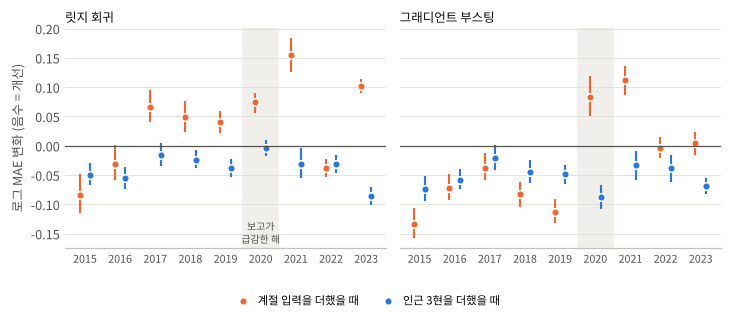

In [55]:
# 부스팅은 입력 끝자리에 따라 셋째 자리가 흔들림(6.4절). 계절 입력을 뺀 나머지 입력에 1e-12 크기의 잡음을 더해 5번 다시 돌려서 방향이 그대로인지 봄
NOISY = [c_ for c_ in OWN + NB + NAT if c_ not in ('ws', 'wc')]
rows = []
for seed in range(5):
    Pn = P.copy(); Pn[NOISY] = Pn[NOISY] + np.random.default_rng(seed).normal(0, 1e-12, (len(Pn), len(NOISY)))
    En = evaluate_years(Pn, W, yw, years=YEARS, models=SP, learner=hgb())
    gap = lambda ys, a, b: log_mae(En[En.eval_year.isin(ys)], a) - log_mae(En[En.eval_year.isin(ys)], b)
    for gname, ys in GROUPS.items():
        rows.append({'seed': seed, '연도': gname, **{f'{short(a)}-{short(b)}': gap(ys, a, b) for a, b in CMP}})
NZ = pd.DataFrame(rows); save(NZ, 'calendar_noise.csv')
display(NZ.groupby('연도', sort=False)[['M1-M1x', 'M2x-M1x', 'M2-M1', 'M4-M3', 'M4x-M3x']].agg(['min', 'max']).round(3))
rho_nz = [spearmanr(YD[SIMS[0]], NZ[(NZ.seed == s) & NZ['연도'].isin(ystr)].set_index('연도').loc[ystr, 'M1-M1x'])[0] for s in range(5)]
print('잡음을 더한 5번에서 계절 입력 효과와 과거 닮음의 순위 상관: %.2f ~ %.2f' % (min(rho_nz), max(rho_nz)))
facts('calendar', {'nb_total': len(nbr), 'nb_neg': int((nbr['차이'] < 0).sum()), 'nb_sig': int((nbr['상한'] < 0).sum()), 'noise_n': 5, 'rho_noise_min': min(rho_nz), 'rho_noise_max': max(rho_nz),
                   'rho_year_sim': rho_year, 'win_rho': win_rho, 'win_rho_x': win_rho_x, 'rand_n': int(RD.seed.nunique())})

fig, axes = plt.subplots(1, 2, figsize=(WD, 2.85), sharey=True)
x = np.arange(len(YEARS))
for ax, (k, ttl) in zip(axes, (('릿지', '릿지 회귀'), ('부스팅', '그래디언트 부스팅'))):
    ax.axvspan(YEARS.index(2020) - 0.5, YEARS.index(2020) + 0.5, color='#f0efec', zorder=0)  # 보고가 급감한 해
    for j, (cmp, lab, col) in enumerate((('M1-M1x', '계절 입력을 더했을 때', B2), ('M2x-M1x', '인근 3현을 더했을 때', B1))):
        xs = x + (j - 0.5) * 0.3  # 겹치지 않게
        ax.vlines(xs, eff(k, cmp, '하한')[ystr], eff(k, cmp, '상한')[ystr], color=col, linewidth=1.4)
        ax.plot(xs, eff(k, cmp)[ystr], 'o', color=col, markersize=5, markeredgecolor='white', markeredgewidth=1.0, linestyle='none', label=lab)
    ax.axhline(0, color=INK2, linewidth=0.8); clean(ax); ax.set_xticks(x); ax.set_xticklabels(ystr, fontsize=7); ax.set_title(ttl, fontsize=8.2, pad=4)
axes[0].set_ylabel('로그 MAE 변화 (음수 = 개선)')
axes[0].text(YEARS.index(2020), axes[0].get_ylim()[0] + 0.004, '보고가\n급감한 해', fontsize=6.5, color=INK2, ha='center', va='bottom', linespacing=1.3)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=2, fontsize=7.4, handletextpad=0.3, columnspacing=1.6)
fig.tight_layout(); fig.subplots_adjust(bottom=0.2); fig.savefig(FIG_DIR / 'fig9_calendar.png'); plt.show()

## 부록 B. SIRS 모의실험 (표 B1)

실제 자료에 맞춘 모형이 아니다. 현 사이 연결 방식만 바꾼 가상 자료를 만들어 같은 예측 평가를 돌린다. 가정에 따라 결과가 바뀌어서 보고서 본문의 근거로는 쓰지 않았다. 조건 10개를 20번씩 돌려서 4분쯤 걸린다.

In [56]:
D = distance_matrix(info); N = info['pop'].to_numpy().astype(float); n = len(N)
mu = W.loc[yw.index[yw.year <= 2019]].mean().to_numpy()
YR, WK = yw.year.to_numpy(), yw.week.to_numpy()

def coupling(kind, ell=100.0):
    # local: 가까울수록, 인구가 많을수록 강한 연결. global: 거리와 무관하게 인구에만 비례
    A = np.tile(N, (n, 1))
    if kind == 'local': A = A * np.exp(-D / ell)
    np.fill_diagonal(A, 0)
    return A / A.sum(axis=1, keepdims=True)

def simulate(kind, m, npi=0.5, seed=0, R0=3.0, amp=0.25, wane=1 / 52, imp=1e-8, burn=520):
    # 주 단위 SIRS. 감염 기간 1주, 면역은 평균 52주 뒤 소실. 자료에 맞춘 값이 아니고 임의로 잡음. 전파율 50% 감소는 대회 FAQ가 예로 든 값
    rng = np.random.default_rng(seed); Cw = coupling(kind)
    t0 = burn + int(np.where((YR == 2020) & (WK == 10))[0][0])  # 코로나 구간 시작
    S = N * 0.4; I = N * 1e-4; R = N - S - I
    out = np.zeros((burn + len(W), n))
    for t in range(len(out)):
        beta = R0 * (1 + amp * np.cos(2 * np.pi * ((t - burn) % 52.18 - 44) / 52.18))
        if t0 <= t < t0 + 52: beta *= 1 - npi  # 1년 동안 전파율을 낮춤
        prev = I / N
        lam = beta * ((1 - m) * prev + m * (Cw @ prev)) + imp  # imp: 나라 밖에서 들어오는 감염. 없으면 연결 없는 경우에 유행이 안 돌아옴
        new = rng.binomial(S.astype(np.int64), 1 - np.exp(-lam)).astype(float)
        back = rng.binomial(R.astype(np.int64), wane).astype(float)
        S, R, I = S - new + back, R + I - back, new
        out[t] = new
    X = out[burn:]
    rho = mu / X[YR <= 2019].mean(axis=0)  # 코로나 전 평균 보고 수가 실제 자료와 같아지도록 보고율을 맞춤
    return pd.DataFrame(rng.poisson(X * rho), index=W.index, columns=W.columns)

def score(Ws, nrand=5):
    E = evaluate_years(build_panel(Ws, yw, info), Ws, yw)
    g = lambda E, a, b: log_mae(E, a) - log_mae(E, b)
    r = {'M0': log_mae(E, M0), 'M1': log_mae(E, M1), 'M3-M1': g(E, M3, M1), 'M2-M1 인근': g(E, M2, M1), 'M4-M3 인근': g(E, M4, M3),
         '0인 값 비율': float((Ws.to_numpy()[YR >= 2021] == 0).mean())}
    rr = []
    for s in range(nrand):
        Er = evaluate_years(build_panel(Ws, yw, info, nb_w=nb_weights(info, 3, 'random', seed=s)), Ws, yw)
        rr.append((g(Er, M2, M1), g(Er, M4, M3)))
    r['M2-M1 무작위'], r['M4-M3 무작위'] = np.mean(rr, axis=0)
    pk = lambda Y: WK[YR == Y][Ws.to_numpy()[YR == Y].argmax(axis=0)]
    r['정점 주 IQR 2019'] = np.subtract(*np.percentile(pk(2019), [75, 25])); r['정점 주 IQR 2021'] = np.subtract(*np.percentile(pk(2021), [75, 25]))
    return r

In [57]:
# 연결 비중 0.5%와 외부 유입 1e-8은 몇 번 돌려 본 뒤에 잡은 값. 비중이 5%면 모든 현이 한꺼번에 움직여서 비교할 것이 없었고, 유입이 1e-9면 연결 없는 조건에서 유행이 안 돌아왔음
CASES = [('연결 없음', 'local', 0.0, 0.5, 1e-8), ('거리와 무관한 연결', 'global', 0.005, 0.5, 1e-8), ('거리에 따라 약해지는 연결', 'local', 0.005, 0.5, 1e-8),
         ('거리에 따라 약해지는 연결, 전파율 30% 감소', 'local', 0.005, 0.3, 1e-8), ('거리에 따라 약해지는 연결, 전파율 70% 감소', 'local', 0.005, 0.7, 1e-8),
         ('거리에 따라 약해지는 연결, 연결 비중 2%', 'local', 0.02, 0.5, 1e-8), ('거리와 무관한 연결, 연결 비중 2%', 'global', 0.02, 0.5, 1e-8),
         ('연결 없음, 외부 유입 10배', 'local', 0.0, 0.5, 1e-7), ('거리와 무관한 연결, 외부 유입 10배', 'global', 0.005, 0.5, 1e-7), ('거리에 따라 약해지는 연결, 외부 유입 10배', 'local', 0.005, 0.5, 1e-7)]
NREP = 20
rows = []
for label, kind, m, npi, imp in CASES:
    for seed in range(NREP):
        rows.append({'조건': label, 'seed': seed, **score(simulate(kind, m, npi, seed, imp=imp))})
    print(label, '끝', flush=True)
SM = pd.DataFrame(rows); save(SM, 'sim_runs.csv')
SM['M4-M3 차이'] = SM['M4-M3 인근'] - SM['M4-M3 무작위']; SM['M2-M1 차이'] = SM['M2-M1 인근'] - SM['M2-M1 무작위']
cols = ['M0', 'M1', 'M3-M1', 'M2-M1 인근', 'M2-M1 무작위', 'M2-M1 차이', 'M4-M3 인근', 'M4-M3 무작위', 'M4-M3 차이', '0인 값 비율', '정점 주 IQR 2019', '정점 주 IQR 2021']
T = SM.groupby('조건', sort=False)[cols].mean()
T['인근이 나은 횟수'] = SM.assign(w=SM['M4-M3 차이'] < 0).groupby('조건', sort=False).w.sum()
T['인근이 오차를 줄인 횟수'] = SM.assign(w=SM['M4-M3 인근'] < 0).groupby('조건', sort=False).w.sum()
save(T.reset_index(), 'sim_summary.csv'); display(T.round(3))

연결 없음 끝


거리와 무관한 연결 끝


거리에 따라 약해지는 연결 끝


거리에 따라 약해지는 연결, 전파율 30% 감소 끝


거리에 따라 약해지는 연결, 전파율 70% 감소 끝


거리에 따라 약해지는 연결, 연결 비중 2% 끝


거리와 무관한 연결, 연결 비중 2% 끝


연결 없음, 외부 유입 10배 끝


거리와 무관한 연결, 외부 유입 10배 끝


거리에 따라 약해지는 연결, 외부 유입 10배 끝


,M0,M1,M3-M1,M2-M1 인근,M2-M1 무작위,M2-M1 차이,M4-M3 인근,M4-M3 무작위,M4-M3 차이,0인 값 비율,정점 주 IQR 2019,정점 주 IQR 2021,인근이 나은 횟수,인근이 오차를 줄인 횟수
조건,,,,,,,,,,,,,,
연결 없음,0.556,0.658,0.220,0.086,0.086,-0.001,0.091,0.143,-0.052,0.624,1.000,32.600,20,0
거리와 무관한 연결,0.853,0.663,-0.007,-0.010,-0.008,-0.002,-0.042,-0.046,0.005,0.126,0.975,1.775,3,20
거리에 따라 약해지는 연결,0.835,0.654,0.032,-0.006,0.027,-0.033,-0.044,-0.022,-0.021,0.136,0.950,2.950,18,20
"거리에 따라 약해지는 연결, 전파율 30% 감소",0.900,0.668,-0.094,-0.061,-0.063,0.002,-0.006,-0.012,0.006,0.103,1.000,0.850,0,20
"거리에 따라 약해지는 연결, 전파율 70% 감소",0.888,0.786,0.020,-0.004,0.019,-0.024,-0.028,-0.010,-0.018,0.371,1.025,2.050,19,20
"거리에 따라 약해지는 연결, 연결 비중 2%",0.957,0.730,-0.047,-0.052,-0.022,-0.029,-0.058,-0.049,-0.009,0.125,0.950,2.400,16,20
"거리와 무관한 연결, 연결 비중 2%",0.986,0.752,-0.089,-0.052,-0.053,0.002,-0.051,-0.066,0.015,0.126,0.950,1.275,0,20
"연결 없음, 외부 유입 10배",0.943,0.767,0.067,0.072,0.077,-0.005,0.031,0.043,-0.012,0.204,0.950,8.375,18,0
"거리와 무관한 연결, 외부 유입 10배",1.039,0.794,-0.091,-0.044,-0.040,-0.004,-0.022,-0.028,0.006,0.132,1.000,3.525,2,20


In [58]:
# 연결이 없어도 인근 3현이 무작위 3현보다 덜 나빴던 이유 확인: 인구가 많은 현일수록 유행이 먼저 돌아오고, 인구가 비슷한 현끼리 모여 있음
nb3 = nearest_k(info); lp = np.log(info['pop'])
rows = []
for seed in range(NREP):
    X = simulate('local', 0.0, 0.5, seed).to_numpy(); thr = 0.1 * X[YR <= 2019].max(axis=0)
    post = np.where(YR >= 2021)[0]
    first = pd.Series([next((t for t in post if X[t, j] >= thr[j]), np.nan) for j in range(n)], index=W.columns)
    f = first.fillna(len(W) + 52)  # 2023년 말까지 유행이 안 돌아온 현은 맨 뒤 순위로
    rows.append({'seed': seed, '복귀 못 한 현': int(first.isna().sum()), '인구와 복귀 시점': spearmanr(lp, f)[0],
                 '자기 현과 인근의 복귀 시점': spearmanr(f, pd.Series({p: np.mean([f[q] for q in nb3[p]]) for p in W.columns}))[0]})
NC = pd.DataFrame(rows); save(NC, 'sim_none_check.csv'); display(NC.drop(columns='seed').mean().round(2))
rho_pop = spearmanr(lp, pd.Series({p: np.mean([lp[q] for q in nb3[p]]) for p in W.columns}))[0]
print('자기 현 인구와 인근 3현 평균 인구의 순위 상관: %.2f' % rho_pop)
facts('sim', {'nrep': NREP, 'rho_pop_nb': rho_pop, **NC.drop(columns='seed').mean().to_dict()})

복귀 못 한 현           7.50
인구와 복귀 시점         -0.51
자기 현과 인근의 복귀 시점    0.24
dtype: float64

자기 현 인구와 인근 3현 평균 인구의 순위 상관: 0.33


## 정리

표는 `results/`에, 그림 1~9는 `figures/`에 저장된다. 5장까지는 중간보고서에서 고정한 설계이고 계산도 중간보고서와 같다.